# Netwerkanalyse

Deze notebook leest dezelfde twee WhatsApp-exports als `Squad_plus_chicks_345.ipynb` rechtstreeks uit de ZIP-bestanden in `data/raw`. Auteursnamen en telefoonnummers blijven ongeanonimiseerd. Systeemberichten worden apart gehouden; auteurs worden op basis van de bestaande classificatie naar `man` of `vrouw` gemapt.

Daarna staan de opdrachten uit de drie notebooks van les 7 bij de eigen chatdata. De opdrachten zijn oefenmateriaal: interpreteer de grafen en resultaten zelf.

In [500]:
import sys
from pathlib import Path

basepath = Path("../..").resolve()
sys.path.insert(0, str(basepath))

from io import TextIOWrapper
import re
from zipfile import ZipFile

import pandas as pd
from IPython.display import display
from wa_analyzer.data import ROOT

In [501]:
ZIP_PATH = ROOT / "data" / "raw" / "Squad plus chicks 🐥.zip"
SQUAD_VOL_ZIP_PATH = ROOT / "data" / "raw" / "Squad vol.zip"
CHAT_DATETIME_FORMAT = "%d-%m-%Y %H:%M"
SQUAD_VOL_DATETIME_FORMAT = "%d-%m-%Y %H:%M"
MESSAGE_HEADER = re.compile(r"^(\d{2}-\d{2}-\d{4} \d{2}:\d{2}) - (.*?): (.*)$")
TIMESTAMPED_LINE = re.compile(r"^(\d{2}-\d{2}-\d{4} \d{2}:\d{2}) - (.*)$")

def read_chat_zip(path, datetime_format, keep_events=False, strip_direction_marks=False):
    if not path.is_file():
        raise FileNotFoundError(f"Chatarchief niet gevonden: {path}")

    with ZipFile(path) as archive:
        text_members = [name for name in archive.namelist() if name.lower().endswith(".txt")]
        if len(text_members) != 1:
            raise ValueError(
                f"Verwacht precies één .txt-chatbestand in {path.name}; "
                f"gevonden: {len(text_members)}."
            )

        message_records = []
        event_records = []
        last_record_kind = None
        continuation_lines = 0
        with TextIOWrapper(archive.open(text_members[0]), encoding="utf-8-sig") as chat_file:
            for line_number, line in enumerate(chat_file, start=1):
                line = line.rstrip("\r\n")
                message_match = MESSAGE_HEADER.match(line)
                if message_match:
                    timestamp_text, author, message = message_match.groups()
                    timestamp = pd.to_datetime(
                        timestamp_text, format=datetime_format, utc=True, errors="raise"
                    )
                    author = author.strip()
                    if strip_direction_marks:
                        author = author.strip("\u200e\u200f")
                    message_records.append((timestamp, author, message.strip()))
                    last_record_kind = "message"
                    continue

                timestamp_match = TIMESTAMPED_LINE.match(line)
                if timestamp_match:
                    if keep_events:
                        timestamp_text, event_text = timestamp_match.groups()
                        timestamp = pd.to_datetime(
                            timestamp_text, format=datetime_format, utc=True, errors="raise"
                        )
                        event_records.append((timestamp, event_text.strip()))
                    last_record_kind = "event"
                    continue

                if last_record_kind == "message":
                    timestamp, author, message = message_records[-1]
                    message_records[-1] = (timestamp, author, f"{message}\n{line}".strip())
                    continuation_lines += 1
                elif keep_events and last_record_kind == "event":
                    timestamp, event_text = event_records[-1]
                    event_records[-1] = (timestamp, f"{event_text}\n{line}".strip())
                    continuation_lines += 1
                elif last_record_kind is None and line.strip():
                    raise ValueError(
                        f"Onverwachte regel zonder tijdstempel of voorafgaand record "
                        f"op regel {line_number} in {path.name}."
                    )

    messages = pd.DataFrame(message_records, columns=["timestamp", "author", "message"])
    events = pd.DataFrame(event_records, columns=["timestamp", "event"])
    messages["message_length"] = messages["message"].str.len()
    return messages, events, continuation_lines

messages, chat_events, continuation_lines = read_chat_zip(
    ZIP_PATH, CHAT_DATETIME_FORMAT, keep_events=True
)
messages = messages.loc[messages["author"].ne("null")].copy()
messages["word_count"] = messages["message"].str.split().str.len()

squad_vol_messages, _, _ = read_chat_zip(
    SQUAD_VOL_ZIP_PATH,
    SQUAD_VOL_DATETIME_FORMAT,
    strip_direction_marks=True,
)
squad_vol_messages = squad_vol_messages.loc[
    squad_vol_messages["author"].ne("+31 6 30621510")
].copy()

print(f"Chatberichten: {len(messages):,}")
print(f"Auteurs (namen ongewijzigd): {messages['author'].nunique():,}")
print(f"Berichten in Squad vol: {len(squad_vol_messages):,}")
print(f"Auteurs in Squad vol (namen uit export): {squad_vol_messages['author'].nunique():,}")
print(f"Systeemgebeurtenissen zonder auteur: {len(chat_events):,}")
print(f"Regels die aan een bericht/gebeurtenis zijn toegevoegd: {continuation_lines:,}")

Chatberichten: 13,034
Auteurs (namen ongewijzigd): 30
Berichten in Squad vol: 65,057
Auteurs in Squad vol (namen uit export): 15
Systeemgebeurtenissen zonder auteur: 41
Regels die aan een bericht/gebeurtenis zijn toegevoegd: 414


## Auteursclassificatie

De classificatie en aliasnormalisatie hieronder volgen `Squad_plus_chicks_345.ipynb`. De telefoonnummers zijn niet geanonimiseerd. In die referentienotebook zijn de telefoonnummers als vrouw geclassificeerd en de auteurs in `Squad vol` als mannen.

In [502]:
author_aliases = {
    "Eikel": "Joel",
    "Vincent": "Vincent Kruithof",
}
for chat in (messages, squad_vol_messages):
    chat["author"] = chat["author"].replace(author_aliases)

author_gender = {
    "Eef": "vrouw",
    "Ijsie": "man",
    "Joel": "man",
    "Kevin": "man",
    "Marijn": "man",
    "Nick": "man",
    "Paul": "man",
    "Rheno": "man",
    "Rik": "man",
    "Rüberhaupt": "man",
    "Schwéhn": "man",
    "Thijsje": "man",
    "Tim Wapenaar": "man",
    "Vincent Kruithof": "man",
    "+31 6 20878246": "vrouw",
    "+31 6 27594625": "vrouw",
    "+31 6 28262831": "vrouw",
    "+31 6 28514891": "vrouw",
    "+31 6 30196468": "vrouw",
    "+31 6 37556157": "vrouw",
    "+31 6 39190988": "vrouw",
    "+31 6 39512381": "vrouw",
    "+31 6 43437377": "vrouw",
    "+31 6 43970301": "vrouw",
    "+31 6 48559406": "vrouw",
    "+31 6 54220861": "vrouw",
    "+31 6 82000019": "vrouw",
    "+31 6 83801855": "vrouw",
}

unclassified_authors = set(messages["author"].unique()) - set(author_gender)
if unclassified_authors:
    raise ValueError(
        f"Geen auteursclassificatie opgegeven voor: {sorted(unclassified_authors)}"
    )

messages["author_gender"] = messages["author"].map(author_gender)
squad_vol_messages["author_gender"] = "man"
author_gender_summary = (
    messages[["author", "author_gender"]]
    .drop_duplicates()
    .sort_values(["author_gender", "author"])
    .reset_index(drop=True)
)
display(author_gender_summary)
print("Berichten per auteursclassificatie:")
display(messages["author_gender"].value_counts().rename_axis("classificatie").to_frame("berichten"))

,author,author_gender
0,Ijsie,man
1,Joel,man
2,Kevin,man
3,Marijn,man
4,Nick,man
5,Paul,man
6,Rheno,man
7,Rik,man
8,Rüberhaupt,man
9,Schwéhn,man


Berichten per auteursclassificatie:


,berichten
classificatie,
man,10460
vrouw,2574


## Netwerk voorbereiden

De nabijheidsregel verbindt twee auteurs wanneer hun berichten binnen het gekozen tijdvenster vallen. Die regel meet samen aanwezig zijn in de chat, niet noodzakelijk een gesprek. Pas `seconds` aan om te zien wat die keuze met het netwerk doet.

In [503]:
import networkx as nx
from wa_analyzer.network_analysis import Config, GraphBuilder

network_messages = messages.dropna(subset=["timestamp", "author"]).copy()

def build_chat_graph(data, seconds):
    config = Config(time_col="timestamp", node_col="author", seconds=seconds, datafile=None)
    return GraphBuilder(config).build(data, edge_seconds=seconds)

## 7.1 Social graphs — wie praat met wie?

### Your turn

WhatsApp heeft geen IRC-nickconventie. Een nabijheidsgraaf is daarom een bruikbare start, maar de regel kan niet onderscheiden wie daadwerkelijk met wie sprak.

1. Bouw de graaf met vensters van 60 seconden en 30 minuten. Verandert de persoon met de hoogste degree? Een stabiel antwoord is ook een resultaat.
2. Degree zegt mogelijk weinig in een kleine groep. Gebruik ook edge weights: welke auteurs wisselen de meeste berichten uit volgens deze regel?
3. Noem een paar dat volgens de graaf verbonden is, maar waarvan je weet dat ze niet met elkaar spraken. Leg uit wat de regel deed.

Leg je edge-regel vast als een zin, benoem wat deze regel niet kan onderscheiden en rapporteer minstens één getal naast een visualisatie.

In [504]:
graphs_by_window = {
    seconds: build_chat_graph(network_messages, seconds)
    for seconds in (60, 30 * 60)
}

for seconds, graph in graphs_by_window.items():
    degrees = pd.Series(dict(graph.degree())).sort_values(ascending=False)
    print(f"{seconds} seconden: {graph.number_of_nodes()} auteurs, "
          f"{graph.number_of_edges()} edges")
    print(degrees.head(8).to_string())
    print("Sterkste gewogen verbindingen:")
    print(sorted(graph.edges(data="weight"), key=lambda edge: edge[2], reverse=True)[:8])

60 seconden: 28 auteurs, 208 edges
Ijsie               26
Rik                 24
Rheno               23
Vincent Kruithof    23
Schwéhn             22
Thijsje             22
Paul                21
Kevin               20
Sterkste gewogen verbindingen:
[('Joel', 'Kevin', 1132), ('Joel', 'Rik', 353), ('Eef', 'Ijsie', 248), ('Vincent Kruithof', 'Kevin', 191), ('Rheno', 'Ijsie', 176), ('Ijsie', 'Kevin', 172), ('Vincent Kruithof', 'Ijsie', 168), ('Schwéhn', 'Ijsie', 166)]
1800 seconden: 28 auteurs, 290 edges
Nick                27
Thijsje             27
Ijsie               27
Rheno               27
Kevin               27
Eef                 26
Vincent Kruithof    26
Schwéhn             26
Sterkste gewogen verbindingen:
[('Joel', 'Kevin', 1451), ('Vincent Kruithof', 'Kevin', 1023), ('Ijsie', 'Kevin', 1007), ('Rheno', 'Ijsie', 976), ('Vincent Kruithof', 'Ijsie', 892), ('Eef', 'Ijsie', 886), ('Thijsje', 'Ijsie', 762), ('Eef', 'Paul', 756)]


### Netwerkgrafieken van beide chats

Net als in les 7.1 gebruiken deze interactieve grafieken de nabijheidsregel met een venster van tien minuten. Nodes met degree 9 of lager worden voor de leesbaarheid weggelaten; de drempel geldt voor de volledige graaf.

In [505]:
from wa_analyzer.network_analysis import GraphVisualizer

viz = GraphVisualizer()
visualization_chats = {
    "Squad plus chicks": network_messages,
    "Squad vol": squad_vol_messages.dropna(subset=["timestamp", "author"]).copy(),
}

for chat_name, chat_data in visualization_chats.items():
    graph = build_chat_graph(chat_data, 10 * 60)
    core = viz.filter_connections(graph, threshold=9)
    print(f"{chat_name}: {core.number_of_nodes()} nodes, {core.number_of_edges()} edges")

    layout_builder = GraphBuilder(
        Config(time_col="timestamp", node_col="author", seconds=10 * 60, datafile=None)
    )
    positions = layout_builder.calculate_layout(core, name="Spring Layout", scale=2.0)
    fig = viz(
        core,
        layout_builder.node_colors(core),
        positions,
        title=f"Nabijheidsnetwerk — {chat_name} (10 minuten)",
        node_scale=0.4,
        edge_scale=0.5,
        node_threshold=9,
    )
    display(fig)

2026-11-15 16:58:56.569 | INFO     | wa_analyzer.network_analysis:filter_connections:381 - Filtering nodes with degree <= 9
2026-11-15 16:58:56.578 | INFO     | wa_analyzer.network_analysis:filter_connections:381 - Filtering nodes with degree <= 9


Squad plus chicks: 26 nodes, 252 edges


2026-11-15 16:58:58.625 | INFO     | wa_analyzer.network_analysis:filter_connections:381 - Filtering nodes with degree <= 9
2026-11-15 16:58:58.625 | INFO     | wa_analyzer.network_analysis:filter_connections:381 - Filtering nodes with degree <= 9


Squad vol: 13 nodes, 78 edges


## 7.2 Graph properties — elke maat is een claim over een regel

### Your turn

Gebruik de tienminutengraaf. Vergelijk weighted degree met het aantal berichten per auteur. Als de correlatie hoger is dan 0,9, benoem dan dat de centraliteitsmaat grotendeels een berichtenteller is. Bereken daarnaast clustering bij vensters van 60 seconden en 30 minuten; rapporteer beide en onderzoek of de rangorde verandert.

Tel ook de componenten en geïsoleerde nodes. Zoek ten slotte een auteur met relatief hoge degree ten opzichte van het aantal berichten. Leg vast welke component je meet en rapporteer getallen, niet alleen een layout.

In [506]:
from scipy.stats import spearmanr
from scripts.graphs import giant_component

graph_10m = build_chat_graph(network_messages, 10 * 60)
largest_component = giant_component(graph_10m)
scores = pd.DataFrame({
    "degree": dict(graph_10m.degree()),
    "weighted_degree": dict(graph_10m.degree(weight="weight")),
    "betweenness": nx.betweenness_centrality(largest_component),
    "clustering": nx.clustering(largest_component),
})
scores["messages"] = network_messages.author.value_counts().reindex(scores.index)
scores["author_gender"] = messages.drop_duplicates("author").set_index("author")["author_gender"].reindex(scores.index)
display(scores.sort_values("weighted_degree", ascending=False).head(10))
print("Spearman weighted degree vs. berichtenaantal:",
      spearmanr(scores.weighted_degree, scores.messages).statistic)
print("Componenten:", nx.number_connected_components(graph_10m))
print("Geïsoleerde nodes:", list(nx.isolates(graph_10m)))

,degree,weighted_degree,betweenness,clustering,messages,author_gender
Kevin,26,5494,0.030162,0.710769,1149,man
Ijsie,27,4567,0.036000,0.686610,1566,man
Vincent Kruithof,24,4015,0.019732,0.760870,1400,man
Schwéhn,24,3777,0.017829,0.778986,985,man
Joel,22,3555,0.008610,0.848485,644,man
Eef,25,3046,0.022289,0.750000,1249,vrouw
Rheno,26,2873,0.027738,0.720000,780,man
Paul,23,2811,0.012189,0.814229,986,man
Thijsje,26,2719,0.030162,0.710769,1280,man
Rik,24,2364,0.015090,0.789855,668,man


Spearman weighted degree vs. berichtenaantal: 0.9627703618335732
Componenten: 1
Geïsoleerde nodes: []


## 7.3 Clusters in graphs — op beide chats

### Your turn

Herhaal de toepasselijke stappen uit les 7.3 voor beide tienminutengrafen. De WhatsApp-chats hebben geen bekende ware communitylabels zoals de karateclub; gender is dus geen ground truth. De topologische clusterchecks gebruiken de grootste component en negeren edge weights, net als het rewired nulmodel.

1. Rapporteer per chat $Q$, het gemiddelde van het degree-preserving rewired nulmodel en $z$ samen — nooit $Q$ alleen.
2. Bekijk de gewone en genormaliseerde Laplaciaan, de Fiedler-split en KMeans voor $k=2$ t/m $5$. Vergelijk KMeans met Louvain; ARI tussen algoritmen is geen ground-truthscore.
3. Rapporteer Louvain-groottes en seed-stabiliteit. Splits iedere chat op de middelste datum en vergelijk de partities met ARI voor gedeelde auteurs.
4. Beschrijf gender en activiteit per Louvain-cluster als externe kenmerken, niet als labels waarop de clustering is getraind of als ware community-indeling.

Rapporteer componenten en hoeveel nodes buiten de grootste component vallen. Spectrale grafieken/layouts zijn diagnostiek; zonder duidelijke eigengap of stabiele nul-/tijdchecks bewijzen ze geen echte communities.

In [507]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from goad_toolkit.visualizer import PlotSettings
from scripts.graphs import GraphPlot, best_partition, giant_component, labels, modularity_check

chat_frames = {
    'Squad plus chicks': network_messages,
    'Squad vol': squad_vol_messages.dropna(subset=['timestamp', 'author']).copy(),
}

chat_graphs = {
    name: build_chat_graph(frame, 10 * 60)
    for name, frame in chat_frames.items()
}

activity_by_chat = {}
observed_days_by_chat = {}
for name, frame in chat_frames.items():
    counts = frame.groupby('author').size().rename('messages')
    observed_days = (frame.timestamp.max().normalize() - frame.timestamp.min().normalize()).days + 1
    authors = frame[['author', 'author_gender']].drop_duplicates('author').set_index('author')
    activity = counts.to_frame().join(authors['author_gender'])
    activity['messages_per_day'] = activity['messages'] / observed_days
    activity_by_chat[name] = activity
    observed_days_by_chat[name] = observed_days

print('Netwerken op basis van tienminuten-nabijheid; weights tellen co-presence, geen directe gesprekken.')

Netwerken op basis van tienminuten-nabijheid; weights tellen co-presence, geen directe gesprekken.


## Analyseplan 7.3 — voortgang

### Stage 1 — vraag en context

- **Data:** `Squad vol` is een bestaande vriendengroep van mannen; `Squad plus chicks` bevat dezelfde mannen en hun vriendinnen. De student weet dat sommige deelnemers introvert zijn en minder chatten.
- **Interesse en verwachting:** deelname/activiteit vergelijken: de vriendinnen zullen vermoedelijk minder actief zijn dan de mannen; ook tussen mannen verwacht de student verschil.
- **Open punt:** de verwachting is nog niet concreet weerlegbaar gemaakt. De student vindt een resultaat zonder duidelijke clusters of met alles dicht bij elkaar oninteressant; de beoogde lezer is voorlopig 'iedereen'.

### Eerste vertaling uit stage 1

- Mogelijke maat voor activiteit: berichten per auteur, met gender uit de bestaande auteursclassificatie. Eerst controleren of beide chats vergelijkbare observatieperioden en complete auteurslabels hebben.
- Een rij voor een activiteitvergelijking zou een auteur zijn; berichten zijn herhaalde observaties binnen die auteur. De verdeling en groepsgroottes moeten daarom op auteursniveau worden gecontroleerd.
- De stappen van 7.3 gaan over netwerkclusters, niet rechtstreeks over berichtenaantallen. Behandel clusterstructuur als een afzonderlijke uitkomst/context en controleer die met een rewired nulmodel, de spectrale structuur en stabiliteit; toets activiteit tegen clusters met een maat die niet voor clustering is gebruikt.
- **Open na stage 1:** precieze activiteitmaat, vergelijkingsopzet en welke 7.3-methoden voor beide chats passend zijn. Stage 2 bespreekt en verfijnt deze keuzes.

### Stage 2 — data en meeteenheden

- **Een rij:** één tijdgestempeld chatbericht; vervolgregels zijn aan het vorige bericht gekoppeld. De activiteitclaim gaat over auteurs, niet over losse berichten.
- **Activiteitsmaten:** aantal berichten per auteur én berichten per totale geobserveerde chatdag. De student stemt hiermee in.
- **Groepslabel:** de bestaande handmatige man/vrouw-classificatie, als werklabel.
- **Netwerk:** de bestaande tienminuten-nabijheidsgraaf voor beide chats; die staat voor samen aanwezig zijn, niet noodzakelijk voor rechtstreeks gesprek.
- **Nog te controleren:** verschillen in observatieperiode, instroom en ontbrekende auteurs/classificaties kunnen de vergelijking beïnvloeden.

### Stage 3 — verdeling en vergelijkbaarheid

- De auteurstellingen zijn sterk ongelijk verdeeld: in `Squad plus chicks` zijn de medianen 780 berichten voor 13 mannen en 59 voor 16 vrouwen; de maxima zijn 1.566 en 1.249. In `Squad vol` zijn de mediaan en het maximum bij 14 mannen 4.456,5 en 10.069 berichten.
- De student concludeert dat enkele auteurs veel actiever zijn dan de typische auteur. Activiteit blijft numeriek; toon de verdeling per auteur en rapporteer medianen/spreiding naast gemiddelden.
- De totale observatieperioden zijn 3.452 dagen (`Squad plus chicks`) en 4.274 dagen (`Squad vol`). Delen door groepsdagen corrigeert niet voor iemands eigen instroom of deelnameperiode.
- De mannen in beide chats zijn deels dezelfde personen; vergelijkingen tussen chats zijn daarom niet onafhankelijk. Controleer later de overlap voordat er een gepaarde vergelijking wordt gemaakt.

### Stage 4 — weergave

- **Hoofdbeeld voor activiteit:** verdelingen, als ECDF per auteur. De student kiest voor de x-as berichten per auteur per totale chatdag en voor de y-as het cumulatieve aandeel auteurs; vergelijk mannen en vrouwen in `Squad plus chicks` en toon ruwe aantallen daarnaast.
- **Alternatief:** een gepaarde relatieplot voor dezelfde mannen in beide chats. Die kan veranderingen binnen persoon tonen, maar beantwoordt niet het man/vrouw-verschil.
- De ECDF vermijdt histogram-binkeuzes en behoudt de verdeling per auteur. De rate gebruikt totale groepsdagen en blijft gevoelig voor individuele instroom/deelnameperioden.
- De 7.3-clusteruitkomsten blijven een aparte structuurdiagnose; een netwerk-layout op zichzelf geldt niet als bewijs voor activiteit of voor echte subgroepen.

### Stage 5 — kritiek op de schets

- Voor uitvoering was dit een schets; na uitvoering zag de student dat de vrouwen-ECDF links van de mannen-ECDF ligt en zei dat dit de verwachting ondersteunt.
- De student noemt als beperking dat vriendinnen tijdens de periode kunnen toetreden of de groep verlaten. De totale-dagen-rate corrigeert niet voor zulke wisselende individuele deelnameperioden.
- De figuur vergelijkt twee curves met directe genderlabels en zonder legenda; de x-assen beginnen bij nul en labels blijven binnen de figuur.

### Stage 6 — verificatie en grenzen

- **Activiteit:** beschrijvend rapporteren met de ECDF en medianen/spreiding; geen significantie- of causaliteitsclaim.
- **Clusterstructuur:** voer de toepasselijke 7.3-controles op beide chats uit: rewired nulmodel (ongewogen topologie met behoud van graden; rapporteer $Q$, nulgemiddelde en $z$), spectrale/Laplaciaan-analyse met Fiedler/KMeans, Louvain en seed-stabiliteit.
- **Tijdstabiliteit:** splits elke chat op de middelste datum en vergelijk Louvain-partities met ARI op gedeelde auteurs.
- Vergelijk clusters met gender en activiteit alleen als externe context, niet als ground truth. Er zijn geen onafhankelijke ware clusterlabels; sla daarom ARI tegen een bekende indeling over (die is alleen beschikbaar voor de karateclub).
- De chatduur per auteur is onbekend; toetredende of vertrekkende vriendinnen kunnen per persoon verschillende blootstelling geven. Rate per totale groepsdag lost dat niet op. Er is geen onafhankelijke hold-out-chat om de bevindingen op te bevestigen.

### Besluit na de zes GOAD-stages

Voer de toepasselijke 07.3-stappen uit voor zowel `Squad plus chicks` als `Squad vol`. Houd de activiteitvergelijking beschrijvend (ECDF, ruwe aantallen, medianen en spreiding); rapporteer de cluster-nulvergelijking, spectrale uitkomsten, Louvain-partities, seed- en tijdstabiliteit en vergelijk clusters met externe kenmerken zonder gender als ground truth te gebruiken. Gebruik gedeelde auteurs voor de tijdsplit-ARI en verzin geen ground-truthlabels. Benoem expliciet de beperkingen van totale chatduur en onbekende individuele deelnameperioden.

## 7.3 op de twee chats

De volgende cellen herhalen de topologische en spectrale controles per chat. De rewired nulvergelijking en de Laplaciaan gebruiken de ongewogen grootste component; kleinere componenten en geïsoleerde auteurs worden apart geteld. De Louvain- en KMeans-partities zijn algoritmische uitkomsten, geen bewezen subgroepen.

In [508]:
cluster_results = {}

for chat_name, graph in chat_graphs.items():
    component_sizes = sorted((len(component) for component in nx.connected_components(graph)), reverse=True)
    core = giant_component(graph)
    nodes = list(core.nodes())
    degree_values = [degree for _, degree in graph.degree()]
    print(f'\n{chat_name}: {graph.number_of_nodes()} auteurs, {graph.number_of_edges()} edges, '
          f'dichtheid={nx.density(graph):.3f}, degreebereik={min(degree_values)}-{max(degree_values)}, '
          f'{len(component_sizes)} componenten, groottes {component_sizes}; '
          f'grootste component {core.number_of_nodes()} auteurs')

    if core.number_of_nodes() < 3 or core.number_of_edges() == 0:
        print('Te weinig verbonden auteurs voor de 7.3-clustercontroles.')
        continue

    null_check = modularity_check(core)
    print(f'Unweighted topology: Q={null_check.q:.3f}, '
          f'rewired Q={null_check.null_mean:.3f} +/- {null_check.null_std:.3f}, '
          f'z={null_check.z:+.2f}; rewires per edge={null_check.swaps_per_edge}')
    if null_check.swaps_per_edge == 0 or not np.isfinite(null_check.z):
        print('LET OP: de degree-preserving nulgrafen zijn niet effectief herschikt; '
              'z is niet interpreteerbaar voor deze chat.')

    adjacency = nx.to_numpy_array(core, nodelist=nodes, weight=None)
    degrees = adjacency.sum(axis=1)
    laplacian = np.diag(degrees) - adjacency
    eigenvalues, eigenvectors = np.linalg.eigh(laplacian)
    order = np.argsort(eigenvalues)
    eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]

    inv_sqrt = np.diag(1 / np.sqrt(np.maximum(degrees, 1e-12)))
    normalized_laplacian = np.eye(len(nodes)) - inv_sqrt @ adjacency @ inv_sqrt
    normalized_values, normalized_vectors = np.linalg.eigh(normalized_laplacian)
    order = np.argsort(normalized_values)
    normalized_values, normalized_vectors = normalized_values[order], normalized_vectors[:, order]
    print(f'Unnormalized eigenvalues: {np.round(eigenvalues[:8], 4)}')
    print(f'Gap after Fiedler (unnormalized): {eigenvalues[2] / eigenvalues[1]:.2f}x')
    print(f'Normalized eigenvalues: {np.round(normalized_values[:8], 4)}')
    print(f'Gap after Fiedler (normalized): {normalized_values[2] / normalized_values[1]:.2f}x')

    fiedler_side = (normalized_vectors[:, 1] > 0).astype(int)
    print(f'Normalized Fiedler sign split: {np.bincount(fiedler_side).tolist()} auteurs')

    louvain_runs = [
        nx.community.louvain_communities(core, weight=None, seed=seed)
        for seed in range(10)
    ]
    louvain_partition = max(
        louvain_runs,
        key=lambda partition: nx.community.modularity(core, partition, weight=None),
    )
    louvain_labels = labels(core, louvain_partition)
    seed_labels = [labels(core, partition).reindex(nodes).to_numpy() for partition in louvain_runs]
    seed_ari = [adjusted_rand_score(a, b) for a, b in combinations(seed_labels, 2)]
    louvain_q = nx.community.modularity(core, louvain_partition, weight=None)
    louvain_sizes = sorted((len(group) for group in louvain_partition), reverse=True)
    print(f'Louvain (unweighted): Q={louvain_q:.3f}, {len(louvain_partition)} communities, '
          f'sizes={louvain_sizes}')
    print(f'Louvain seed stability (10 runs): ARI {np.mean(seed_ari):.3f} +/- {np.std(seed_ari):.3f}')

    spectral_rows = []
    kmeans_labels = {}
    for k in range(2, min(5, len(nodes) - 1) + 1):
        embedding = normalized_vectors[:, 1:k + 1]
        embedding = embedding / np.maximum(np.linalg.norm(embedding, axis=1, keepdims=True), 1e-12)
        assignment = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(embedding)
        communities = [{nodes[i] for i in np.where(assignment == group)[0]} for group in range(k)]
        spectral_q = nx.community.modularity(core, communities, weight=None)
        spectral_rows.append({
            'k': k,
            'sizes': sorted(np.bincount(assignment).tolist(), reverse=True),
            'Q': spectral_q,
            'ARI vs Louvain': adjusted_rand_score(assignment, louvain_labels.reindex(nodes).to_numpy()),
        })
        kmeans_labels[k] = pd.Series(assignment, index=nodes, name='cluster')
    display(pd.DataFrame(spectral_rows).round(3))

    cluster_results[chat_name] = {
        'core': core,
        'eigenvalues': eigenvalues,
        'normalized_values': normalized_values,
        'fiedler_side': pd.Series(fiedler_side, index=nodes),
        'kmeans_labels': kmeans_labels,
        'louvain_partition': louvain_partition,
        'louvain_labels': louvain_labels,
    }

    features = activity_by_chat[chat_name].reindex(louvain_labels.index)
    by_cluster = features.assign(cluster=louvain_labels).groupby('cluster')
    display(by_cluster.agg(
        authors=('messages', 'size'),
        median_messages=('messages', 'median'),
        median_messages_per_day=('messages_per_day', 'median'),
    ).round(3))
    display(pd.crosstab(louvain_labels, features['author_gender'],
                        rownames=['cluster'], colnames=['author_gender']))


Squad plus chicks: 28 auteurs, 268 edges, dichtheid=0.709, degreebereik=8-27, 1 componenten, groottes [28]; grootste component 28 auteurs


Unweighted topology: Q=0.042, rewired Q=0.041 +/- 0.003, z=+0.42; rewires per edge=10
Unnormalized eigenvalues: [-0.      7.6683  7.9877  9.7767 10.0931 11.0652 12.9558 13.7877]
Gap after Fiedler (unnormalized): 1.04x
Normalized eigenvalues: [0.     0.7937 0.8456 0.8711 0.8859 0.9025 0.9392 0.9638]
Gap after Fiedler (normalized): 1.07x
Normalized Fiedler sign split: [14, 14] auteurs
Louvain (unweighted): Q=0.044, 3 communities, sizes=[11, 11, 6]
Louvain seed stability (10 runs): ARI 0.305 +/- 0.309


,k,sizes,Q,ARI vs Louvain
0,2,"[14, 14]",0.033,0.309
1,3,"[10, 10, 8]",0.028,0.291
2,4,"[10, 9, 5, 4]",0.017,0.100
3,5,"[7, 6, 6, 5, 4]",0.022,0.228


,authors,median_messages,median_messages_per_day
cluster,,,
0,11,408.0,0.118
1,11,86.0,0.025
2,6,143.0,0.041


author_gender,man,vrouw
cluster,,
0,5,6
1,5,6
2,3,3



Squad vol: 13 auteurs, 78 edges, dichtheid=1.000, degreebereik=12-12, 1 componenten, groottes [13]; grootste component 13 auteurs
Unweighted topology: Q=0.000, rewired Q=0.000 +/- 0.000, z=+nan; rewires per edge=0
LET OP: de degree-preserving nulgrafen zijn niet effectief herschikt; z is niet interpreteerbaar voor deze chat.
Unnormalized eigenvalues: [ 0. 13. 13. 13. 13. 13. 13. 13.]
Gap after Fiedler (unnormalized): 1.00x
Normalized eigenvalues: [0.     1.0833 1.0833 1.0833 1.0833 1.0833 1.0833 1.0833]
Gap after Fiedler (normalized): 1.00x
Normalized Fiedler sign split: [11, 2] auteurs
Louvain (unweighted): Q=0.000, 1 communities, sizes=[13]
Louvain seed stability (10 runs): ARI 1.000 +/- 0.000


,k,sizes,Q,ARI vs Louvain
0,2,"[7, 6]",-0.041,0.0
1,3,"[7, 4, 2]",-0.049,0.0
2,4,"[4, 3, 3, 3]",-0.062,0.0
3,5,"[4, 3, 3, 2, 1]",-0.064,0.0


,authors,median_messages,median_messages_per_day
cluster,,,
0,13,4525.0,1.059


author_gender,man
cluster,
0,13


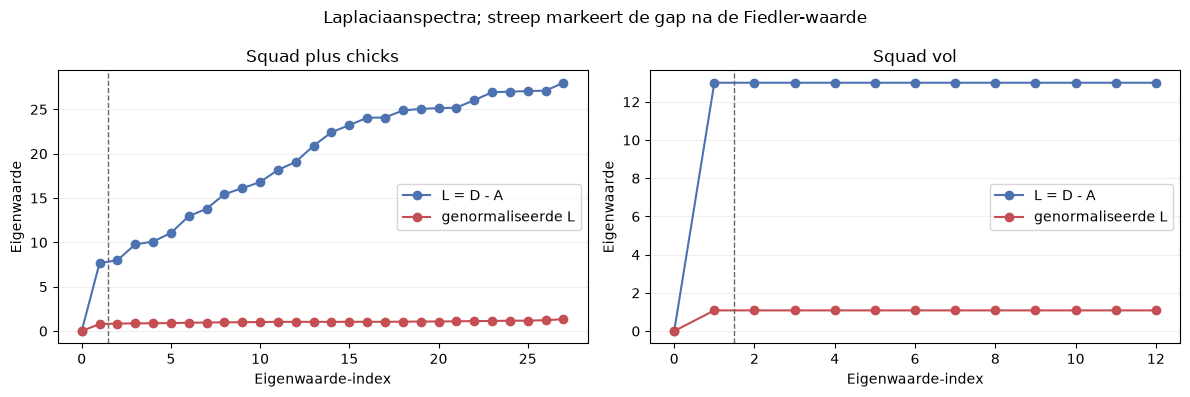

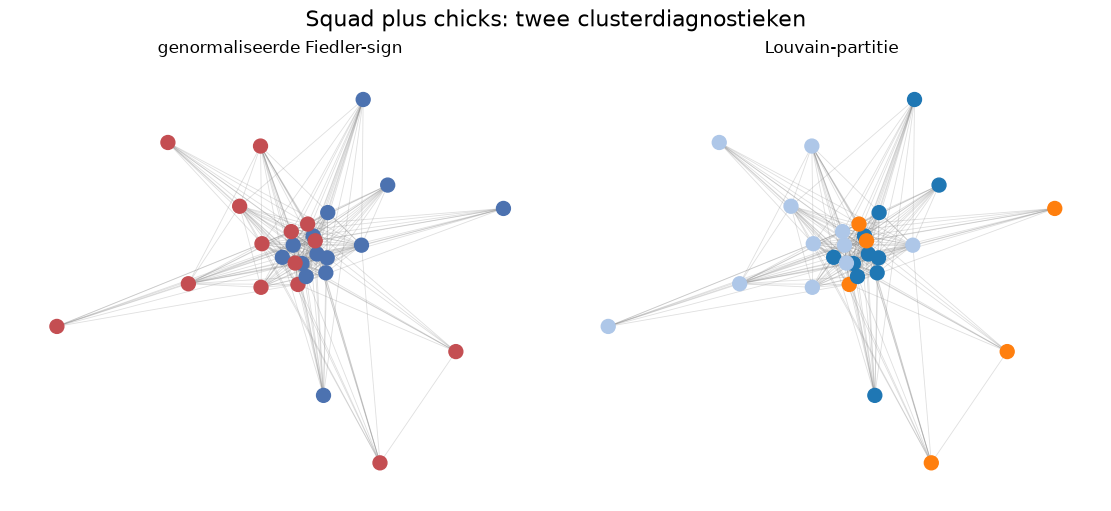

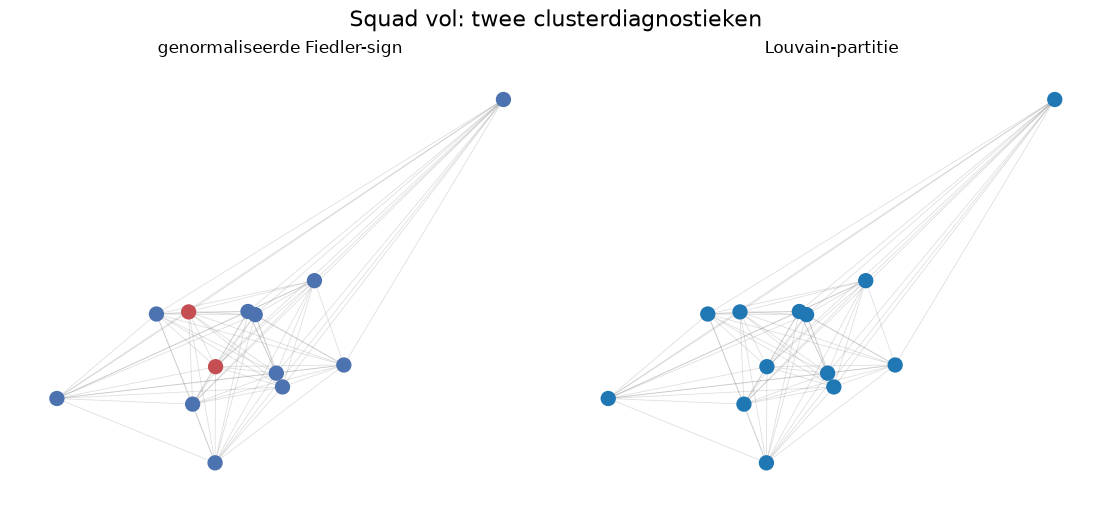

In [509]:
fig, axes = plt.subplots(1, len(cluster_results), figsize=(12, 4))
if len(cluster_results) == 1:
    axes = [axes]

for ax, (chat_name, result) in zip(axes, cluster_results.items(), strict=True):
    ax.plot(result['eigenvalues'], marker='o', color='#4c72b0', label='L = D - A')
    ax.plot(result['normalized_values'], marker='o', color='#c44e52', label='genormaliseerde L')
    ax.axvline(1.5, color='0.4', linestyle='--', linewidth=1)
    ax.set_title(chat_name)
    ax.set_xlabel('Eigenwaarde-index')
    ax.set_ylabel('Eigenwaarde')
    ax.grid(axis='y', alpha=0.2)
    ax.legend()
fig.suptitle('Laplaciaanspectra; streep markeert de gap na de Fiedler-waarde')
fig.tight_layout()
display(fig)
plt.close(fig)

for chat_name, result in cluster_results.items():
    core = result['core']
    positions = nx.spring_layout(core, seed=46)
    settings = PlotSettings(
        figsize=(11, 5), max_cols=2,
        title=f'{chat_name}: twee clusterdiagnostieken',
        subplot_titles=['genormaliseerde Fiedler-sign', 'Louvain-partitie'],
    )
    host = GraphPlot(settings)
    fig, axes = host.create_figure(n_plots=2)
    fiedler_colors = ['#4c72b0' if side == 0 else '#c44e52'
                      for side in result['fiedler_side'].reindex(core.nodes())]
    louvain_colors = [plt.get_cmap('tab20')(int(group) % 20)
                      for group in result['louvain_labels'].reindex(core.nodes())]
    host.plot_on_axes(GraphPlot(settings), axes[0], data=core, pos=positions,
                      color=fiedler_colors, node_size=100, with_labels=False)
    host.plot_on_axes(GraphPlot(settings), axes[1], data=core, pos=positions,
                      color=louvain_colors, node_size=100, with_labels=False)
    display(fig)
    plt.close(fig)

### Tijdstabiliteit en activiteit per cluster

ARI vergelijkt hier twee algoritmische partities op auteurs die in beide tijdvakken voorkomen. Het is een stabiliteitsmaat, geen vergelijking met een ware indeling.

In [510]:
for chat_name, frame in chat_frames.items():
    midpoint = frame.timestamp.min() + (frame.timestamp.max() - frame.timestamp.min()) / 2
    partitions = {}
    component_sizes = {}
    for period, subset in {
        'eerste helft': frame[frame.timestamp < midpoint],
        'tweede helft': frame[frame.timestamp >= midpoint],
    }.items():
        if subset.empty:
            print(f'{chat_name}: {period} bevat geen berichten; ARI niet berekend.')
            continue
        period_graph = build_chat_graph(subset, 10 * 60)
        if period_graph.number_of_nodes() < 2 or period_graph.number_of_edges() == 0:
            print(f'{chat_name}: {period} heeft onvoldoende edges; ARI niet berekend.')
            continue
        period_core = giant_component(period_graph)
        component_sizes[period] = period_core.number_of_nodes()
        if period_core.number_of_nodes() < 2 or period_core.number_of_edges() == 0:
            print(f'{chat_name}: {period} heeft geen clusterbare component; ARI niet berekend.')
            continue
        partitions[period] = labels(period_core, best_partition(period_core, weight=None))

    if len(partitions) == 2:
        first = partitions['eerste helft']
        second = partitions['tweede helft']
        shared = sorted(set(first.index) & set(second.index))
        if len(shared) >= 2:
            ari = adjusted_rand_score(first.reindex(shared), second.reindex(shared))
            print(f'{chat_name}: middelste datum {midpoint.date()}, '
                  f'grootste componenten {component_sizes}, gedeeld {len(shared)} auteurs, ARI={ari:.3f}')
        else:
            print(f'{chat_name}: minder dan twee gedeelde auteurs; ARI niet betekenisvol.')
    else:
        print(f'{chat_name}: geen ARI; beide helften moeten clusterbaar zijn.')

Squad plus chicks: middelste datum 2022-01-18, grootste componenten {'eerste helft': 22, 'tweede helft': 23}, gedeeld 17 auteurs, ARI=-0.069
Squad vol: middelste datum 2020-11-12, grootste componenten {'eerste helft': 12, 'tweede helft': 13}, gedeeld 12 auteurs, ARI=1.000


### Activiteit per auteur

De ECDF vergelijkt de auteurs in `Squad plus chicks`; het tweede paneel toont ruwe aantallen naast berichten per totale chatdag. De gepaarde figuur toont alleen gedeelde mannen in beide exports. Geen van beide figuren corrigeert voor individuele instroom of stille deelnemers die nooit een bericht stuurden.

,authors,messages_median,messages_q25,messages_q75,messages_mean,messages_per_day_median,messages_per_day_q25,messages_per_day_q75,messages_per_day_mean
author_gender,,,,,,,,,
man,13,780.0,392.0,1149.0,804.615,0.226,0.114,0.333,0.233
vrouw,15,42.0,18.5,145.5,171.600,0.012,0.005,0.042,0.050


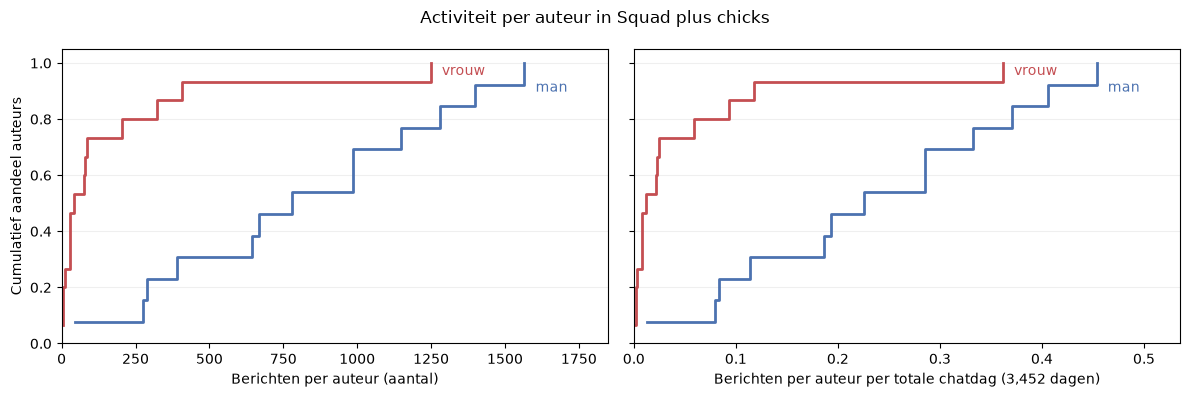

Gedeelde mannen in beide chats: 13


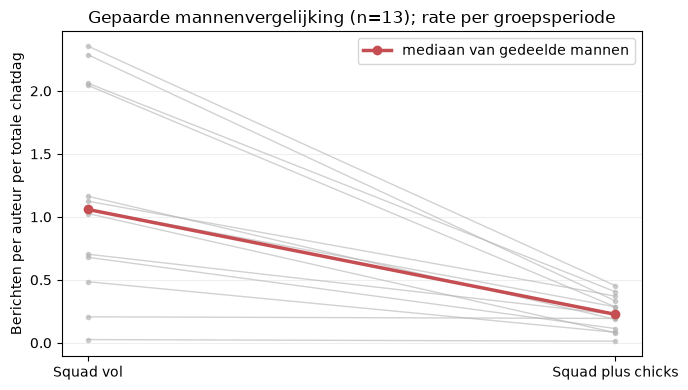

,mediaan berichten per totale chatdag
messages_per_day_squad_vol,1.058727
messages_per_day_plus_chicks,0.225956


In [511]:
mixed_chat = activity_by_chat['Squad plus chicks']
gender_colors = {'man': '#4c72b0', 'vrouw': '#c44e52'}
activity_summary = mixed_chat.groupby('author_gender').agg(
    authors=('messages', 'size'),
    messages_median=('messages', 'median'),
    messages_q25=('messages', lambda values: values.quantile(0.25)),
    messages_q75=('messages', lambda values: values.quantile(0.75)),
    messages_mean=('messages', 'mean'),
    messages_per_day_median=('messages_per_day', 'median'),
    messages_per_day_q25=('messages_per_day', lambda values: values.quantile(0.25)),
    messages_per_day_q75=('messages_per_day', lambda values: values.quantile(0.75)),
    messages_per_day_mean=('messages_per_day', 'mean'),
)
display(activity_summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, column, xlabel in [
    (axes[0], 'messages', 'Berichten per auteur (aantal)'),
    (axes[1], 'messages_per_day',
     f"Berichten per auteur per totale chatdag ({observed_days_by_chat['Squad plus chicks']:,} dagen)"),
]:
    for gender, group in mixed_chat.groupby('author_gender'):
        values = np.sort(group[column].to_numpy(dtype=float))
        cumulative = np.arange(1, len(values) + 1) / len(values)
        color = gender_colors[gender]
        ax.step(values, cumulative, where='post', color=color, linewidth=2)
        offset = (8, -6) if gender == 'vrouw' else (8, -18)
        ax.annotate(gender, xy=(values[-1], 1), xytext=offset,
                    textcoords='offset points', color=color, va='center')
    ax.set_xlabel(xlabel)
    ax.set_ylim(0, 1.05)
    ax.set_xlim(left=0, right=float(mixed_chat[column].max()) * 1.18)
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Cumulatief aandeel auteurs')
fig.suptitle('Activiteit per auteur in Squad plus chicks')
fig.tight_layout()
display(fig)
plt.close(fig)

men_in_mixed_chat = mixed_chat[mixed_chat.author_gender == 'man'][['messages', 'messages_per_day']]
men_in_squad_vol = activity_by_chat['Squad vol'][['messages', 'messages_per_day']]
paired_men = men_in_squad_vol.join(men_in_mixed_chat, how='inner',
                                   lsuffix='_squad_vol', rsuffix='_plus_chicks')
print(f'Gedeelde mannen in beide chats: {len(paired_men)}')
if not paired_men.empty:
    fig, ax = plt.subplots(figsize=(7, 4))
    for _, row in paired_men.iterrows():
        ax.plot([0, 1], [row['messages_per_day_squad_vol'], row['messages_per_day_plus_chicks']],
                color='0.7', alpha=0.6, linewidth=1, marker='o', markersize=3)
    medians = paired_men[['messages_per_day_squad_vol', 'messages_per_day_plus_chicks']].median()
    ax.plot([0, 1], medians.to_numpy(), color='#c44e52', linewidth=2.5, marker='o',
            label='mediaan van gedeelde mannen')
    ax.set_xticks([0, 1], ['Squad vol', 'Squad plus chicks'])
    ax.set_ylabel('Berichten per auteur per totale chatdag')
    ax.set_title(f'Gepaarde mannenvergelijking (n={len(paired_men)}); rate per groepsperiode')
    ax.grid(axis='y', alpha=0.2)
    ax.legend()
    fig.tight_layout()
    display(fig)
    plt.close(fig)
    display(medians.rename('mediaan berichten per totale chatdag').to_frame())

## Connecties in Squad vol

Deze bekende relaties zijn als ongerichte verbindingen gecodeerd. De twee schoolniveaus blijven apart; `school_connections` telt unieke schoolgenoten over beide niveaus en `total_connections` telt iedere andere auteur maximaal één keer, ook wanneer er meerdere soorten relatie zijn. `Vincent` is dezelfde auteur als `Vincent Kruithof`; de opgegeven `Thijs` is `Thijsje` en `Tim` is `Tim Wapenaar`. De auteur waarvoor geen relatie is opgegeven blijft als node/featuresrij staan zonder bekende connecties. De relaties zijn opgegeven categorieën, geen uit de chat afgeleide feiten.

Auteurs: 13; unieke auteurparen met een bekende relatie: 46
Features: 58 totaal, waaronder 52 peer-specifieke relatie-indicatoren.
basisschool: 1 opgegeven groep(en), 15 relatieparen
middelbare_school: 2 opgegeven groep(en), 27 relatieparen
korfbal: 1 opgegeven groep(en), 3 relatieparen
werk: 4 opgegeven groep(en), 13 relatieparen


,basisschool_connections,middelbare_school_connections,school_connections,korfbal_connections,werk_connections,total_connections
author,,,,,,
Ijsie,0,6,6,0,4,7
Joel,5,3,6,2,1,8
Kevin,5,3,6,0,1,6
Marijn,0,0,0,0,4,4
Nick,0,3,3,0,1,4
Paul,5,0,5,2,1,6
Rheno,0,6,6,0,4,7
Rik,5,6,10,0,0,10
Rüberhaupt,5,6,10,0,5,12


,auteur,aantal_buren
0,Rüberhaupt,12
1,Rik,10
2,Joel,8
3,Thijsje,8
4,Ijsie,7
5,Rheno,7
6,Schwéhn,7
7,Vincent Kruithof,7
8,Kevin,6
9,Paul,6


,author_a,author_b,relations
0,Ijsie,Marijn,werk
1,Ijsie,Rheno,"middelbare_school, werk"
2,Ijsie,Rik,middelbare_school
3,Ijsie,Rüberhaupt,"middelbare_school, werk"
4,Ijsie,Schwéhn,"middelbare_school, werk"
5,Ijsie,Thijsje,middelbare_school
6,Ijsie,Vincent Kruithof,middelbare_school
7,Joel,Kevin,"basisschool, middelbare_school"
8,Joel,Nick,middelbare_school
9,Joel,Paul,"basisschool, korfbal"


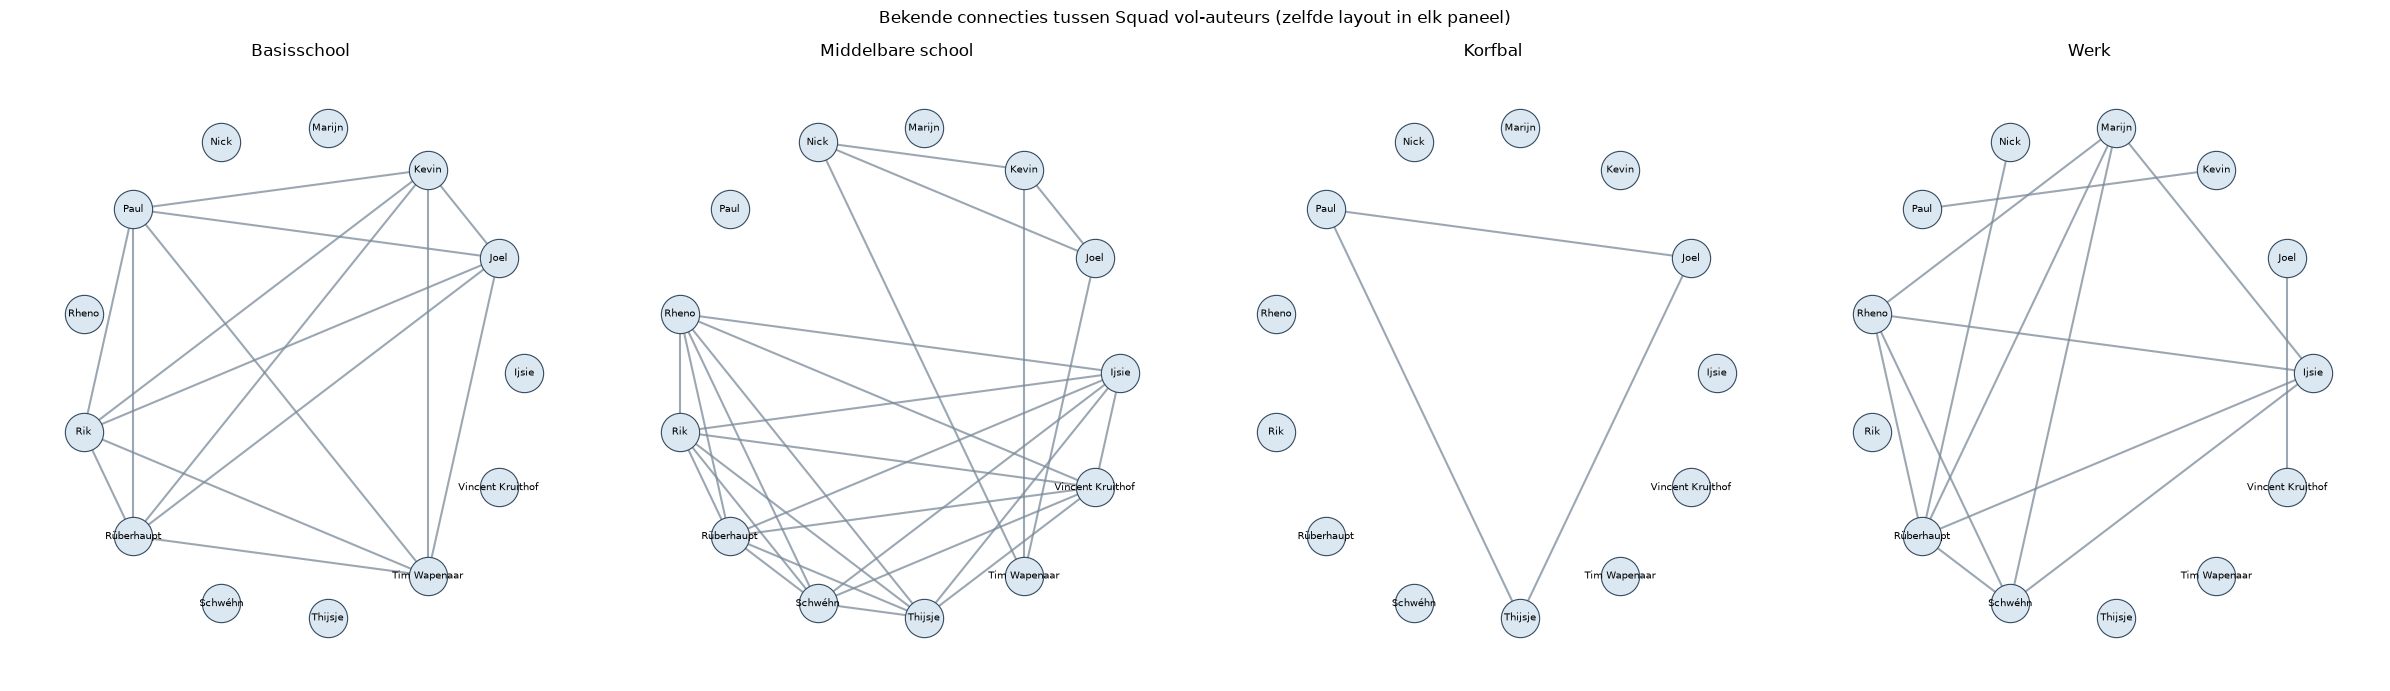

In [512]:
from itertools import combinations

squad_vol_authors = sorted(squad_vol_messages['author'].dropna().unique(), key=str.casefold)
author_by_casefold = {author.casefold(): author for author in squad_vol_authors}
connection_aliases = {
    'Vincent': 'Vincent Kruithof',
    'Thijs': 'Thijsje',
}

def resolve_connection_author(name):
    canonical = connection_aliases.get(name, name)
    author = author_by_casefold.get(canonical.casefold())
    if author is None:
        raise ValueError(f'Onbekende Squad vol-auteur in connectielijst: {name!r}')
    return author

connection_groups = {
    'basisschool': [['Paul', 'Tim Wapenaar', 'Rüberhaupt', 'Rik', 'Kevin', 'Joel']],
    'middelbare_school': [[
        'Rheno', 'Rüberhaupt', 'Thijs', 'Vincent', 'Schwéhn', 'Ijsie', 'Rik',
        'Vincent Kruithof',
    ], ['Joel', 'Tim Wapenaar', 'Kevin', 'Nick']],
    'korfbal': [['Thijs', 'Paul', 'Joel']],
    'werk': [
        ['Rheno', 'Schwéhn', 'Ijsie', 'Rüberhaupt', 'Marijn'],
        ['Vincent', 'Joel'],
        ['Paul', 'Kevin'],
        ['Rüberhaupt', 'Nick'],
    ],
}

connection_groups = {
    relation: [
        sorted({resolve_connection_author(name) for name in members}, key=str.casefold)
        for members in groups
    ]
    for relation, groups in connection_groups.items()
}

relation_peers = {relation: {author: set() for author in squad_vol_authors}
                  for relation in connection_groups}
combined_connections = nx.Graph()
combined_connections.add_nodes_from(squad_vol_authors)
for relation, groups in connection_groups.items():
    for members in groups:
        for author_a, author_b in combinations(members, 2):
            relation_peers[relation][author_a].add(author_b)
            relation_peers[relation][author_b].add(author_a)
            if combined_connections.has_edge(author_a, author_b):
                combined_connections[author_a][author_b]['relations'].add(relation)
            else:
                combined_connections.add_edge(author_a, author_b, relations={relation})

school_peers = {
    author: relation_peers['basisschool'][author] | relation_peers['middelbare_school'][author]
    for author in squad_vol_authors
}
all_peers = {
    author: set().union(*(relation_peers[relation][author] for relation in connection_groups))
    for author in squad_vol_authors
}

connection_features = pd.DataFrame(index=squad_vol_authors)
for relation, peers_by_author in relation_peers.items():
    for author in squad_vol_authors:
        connection_features[f'{relation}__met_{author}'] = [
            int(author in peers_by_author[other_author]) for other_author in squad_vol_authors
        ]
    connection_features[f'{relation}_connections'] = [
        len(peers_by_author[author]) for author in squad_vol_authors
    ]

connection_features['school_connections'] = [
    len(school_peers[author]) for author in squad_vol_authors
]
connection_features['total_connections'] = [
    len(all_peers[author]) for author in squad_vol_authors
]
connection_features.index.name = 'author'

for relation, peers_by_author in relation_peers.items():
    expected_peer_counts = {
        author: sum(len(group) - 1 for group in connection_groups[relation] if author in group)
        for author in squad_vol_authors
    }
    for author, peers in peers_by_author.items():
        if any(author not in peers_by_author[peer] for peer in peers):
            raise ValueError(f'Connecties voor {relation} zijn niet wederkerig.')
        if len(peers) != expected_peer_counts[author]:
            raise ValueError(f'Connectietelling voor {relation} komt niet overeen met de groepen.')
if (connection_features['total_connections'] > connection_features[
        ['basisschool_connections', 'middelbare_school_connections',
         'korfbal_connections', 'werk_connections']
    ].sum(axis=1)).any():
    raise ValueError('Totaal unieke connecties overschrijdt de som van type-connecties.')

connection_edges = pd.DataFrame(
    [
        {'author_a': author_a, 'author_b': author_b,
         'relations': ', '.join(sorted(attributes['relations']))}
        for author_a, author_b, attributes in combined_connections.edges(data=True)
    ]
).sort_values(['author_a', 'author_b']).reset_index(drop=True)

print(f'Auteurs: {len(squad_vol_authors)}; unieke auteurparen met een bekende relatie: '
      f'{combined_connections.number_of_edges()}')
print(f'Features: {connection_features.shape[1]} totaal, waaronder '
      f'{len(squad_vol_authors) * len(connection_groups)} peer-specifieke relatie-indicatoren.')
for relation, groups in connection_groups.items():
    print(f'{relation}: {len(groups)} opgegeven groep(en), '
          f'{sum(len(group) * (len(group) - 1) // 2 for group in groups)} relatieparen')
display(connection_features[[
    'basisschool_connections', 'middelbare_school_connections',
    'school_connections', 'korfbal_connections', 'werk_connections',
    'total_connections',
]])
neighbor_counts = pd.DataFrame({
    'auteur': squad_vol_authors,
    'aantal_buren': [len(all_peers[author]) for author in squad_vol_authors],
}).sort_values(
    ['aantal_buren', 'auteur'], ascending=[False, True],
).reset_index(drop=True)
display(neighbor_counts)
display(connection_edges)

connection_graphs = {}
for relation in connection_groups:
    graph = nx.Graph()
    graph.add_nodes_from(squad_vol_authors)
    for author_a, author_b, attributes in combined_connections.edges(data=True):
        if relation in attributes['relations']:
            graph.add_edge(author_a, author_b)
    connection_graphs[relation] = graph

positions = nx.circular_layout(combined_connections)
display_labels = {
    author: 'Overige auteur' if author.startswith('+') else author
    for author in squad_vol_authors
}
fig, axes = plt.subplots(1, len(connection_graphs), figsize=(24, 7))
for ax, (relation, graph) in zip(axes, connection_graphs.items(), strict=True):
    nx.draw_networkx_edges(graph, positions, ax=ax, edge_color='#7a8a99', width=1.5, alpha=0.75)
    nx.draw_networkx_nodes(
        graph, positions, ax=ax, node_color='#dbe8f2', edgecolors='#34495e',
        node_size=760, linewidths=0.8,
    )
    nx.draw_networkx_labels(graph, positions, labels=display_labels, ax=ax, font_size=7)
    ax.set_title(relation.replace('_', ' ').capitalize())
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.25, 1.25)
    ax.set_axis_off()
fig.suptitle('Bekende connecties tussen Squad vol-auteurs (zelfde layout in elk paneel)')
fig.tight_layout()
display(fig)
plt.close(fig)

### Gecombineerd netwerk van alle connecties

Zoals bij de karateclubfiguur in 07.3 staan twee weergaven van hetzelfde netwerk naast elkaar, met dezelfde posities en auteurslabels: eerst de volledige graaf, daarna dezelfde graaf met connectietypen in kleur. Meerdere connectietypen tussen hetzelfde paar blijven aparte gebogen lijnen.

C:\Users\BVPDIJK\AppData\Local\Temp\ipykernel_43352\79214955.py:84: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


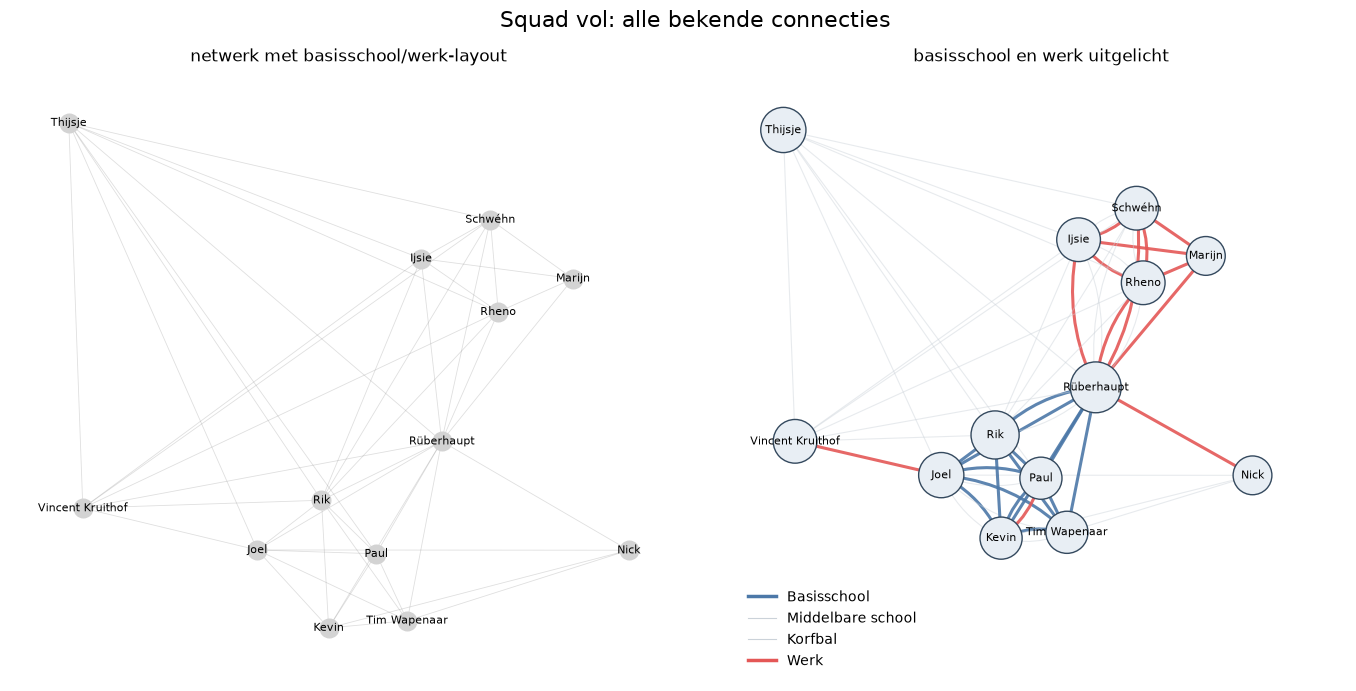

C:\Users\BVPDIJK\AppData\Local\Temp\ipykernel_43352\79214955.py:145: UserWarning: The figure layout has changed to tight
  centrality_fig.tight_layout()


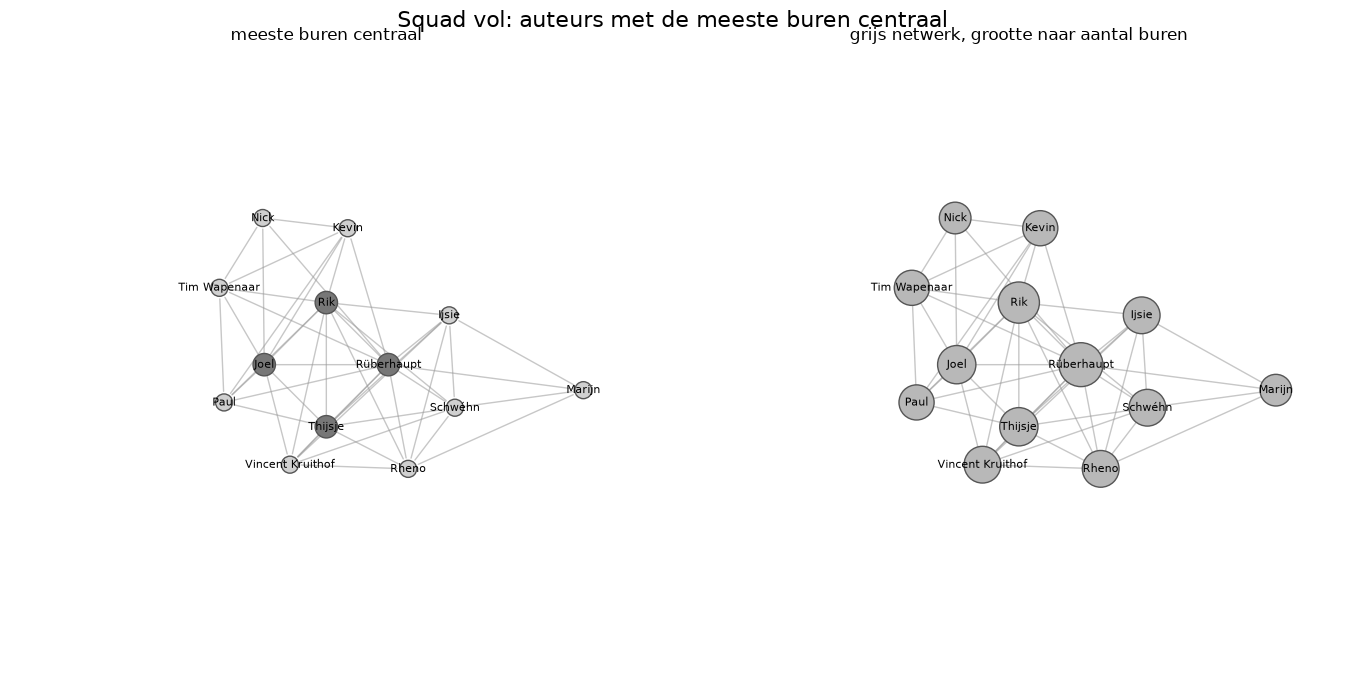

In [513]:
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch

relation_colors = {
    'basisschool': '#4c78a8',
    'middelbare_school': '#f58518',
    'korfbal': '#54a24b',
    'werk': '#e45756',
}
plot_connections = combined_connections.copy()
plot_connections.remove_nodes_from([
    author for author in plot_connections
    if display_labels[author] == 'Overige auteur'
])
plot_labels = {author: display_labels[author] for author in plot_connections}
for _, _, attributes in plot_connections.edges(data=True):
    attributes['layout_weight'] = (
        4.0 if attributes['relations'] & {'basisschool', 'werk'} else 0.1
    )
combined_positions = nx.spring_layout(
    plot_connections, seed=46, k=1.1, iterations=300,
    weight='layout_weight', scale=1.35,
)
connection_plot = PlotSettings(
    figsize=(14, 7), max_cols=2,
    title='Squad vol: alle bekende connecties',
    subplot_titles=['netwerk met basisschool/werk-layout', 'basisschool en werk uitgelicht'],
)
host = GraphPlot(connection_plot)
fig, axes = host.create_figure(n_plots=2)
host.plot_on_axes(
    GraphPlot(connection_plot), axes[0], data=plot_connections,
    pos=combined_positions, node_size=180, with_labels=False,
)
nx.draw_networkx_labels(
    plot_connections, combined_positions, labels=plot_labels,
    ax=axes[0], font_size=8,
)
ax = axes[1]

for author_a, author_b, attributes in plot_connections.edges(data=True):
    relations = sorted(attributes['relations'])
    if len(relations) == 1:
        radii = [0.0]
    else:
        radii = np.linspace(-0.18, 0.18, len(relations)).tolist()
    for relation, radius in zip(relations, radii, strict=True):
        prominent = relation in {'basisschool', 'werk'}
        ax.add_patch(FancyArrowPatch(
            combined_positions[author_a], combined_positions[author_b],
            arrowstyle='-', connectionstyle=f'arc3,rad={radius}',
            color=relation_colors[relation] if prominent else '#cbd2d9',
            linewidth=2.2 if prominent else 0.8,
            alpha=0.9 if prominent else 0.45,
            shrinkA=9, shrinkB=9,
        ))

node_sizes = [
    500 + 70 * connection_features.loc[author, 'total_connections']
    for author in plot_connections.nodes()
]
nx.draw_networkx_nodes(
    plot_connections, combined_positions, ax=ax,
    node_size=node_sizes, node_color='#e8eef4',
    edgecolors='#34495e', linewidths=1.0,
)
nx.draw_networkx_labels(
    plot_connections, combined_positions, labels=plot_labels,
    ax=ax, font_size=8,
)
legend = [
    Line2D(
        [0], [0], color=color if relation in {'basisschool', 'werk'} else '#cbd2d9',
        linewidth=2.5 if relation in {'basisschool', 'werk'} else 0.8,
        label=relation.replace('_', ' ').capitalize(),
    )
    for relation, color in relation_colors.items()
]
ax.legend(handles=legend, loc='lower left', frameon=False)
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.6)
ax.set_aspect('equal')
ax.set_axis_off()
fig.tight_layout()
display(fig)
plt.close(fig)

author_degrees = dict(plot_connections.degree())
central_authors = sorted(
    author_degrees, key=lambda author: (-author_degrees[author], author.casefold())
)[:4]
central_positions = nx.circular_layout(plot_connections, scale=1.15)
for index, author in enumerate(central_authors):
    angle = 2 * np.pi * index / len(central_authors)
    central_positions[author] = np.array([0.5 * np.cos(angle), 0.5 * np.sin(angle)])
for author_a, author_b in plot_connections.edges():
    plot_connections[author_a][author_b]['centrality_layout_weight'] = (
        2.0 if author_a in central_authors or author_b in central_authors else 0.2
    )
central_positions = nx.spring_layout(
    plot_connections, pos=central_positions, fixed=central_authors, seed=46,
    k=1.0, iterations=300, weight='centrality_layout_weight',
)
position_extent = max(np.abs(position).max() for position in central_positions.values())
central_positions = {
    author: position * (1.3 / position_extent)
    for author, position in central_positions.items()
}
centrality_plot = PlotSettings(
    figsize=(14, 7), max_cols=2,
    title='Squad vol: auteurs met de meeste buren centraal',
    subplot_titles=['meeste buren centraal', 'grijs netwerk, grootte naar aantal buren'],
)
centrality_host = GraphPlot(centrality_plot)
centrality_fig, centrality_axes = centrality_host.create_figure(n_plots=2)
for ax in centrality_axes:
    for author_a, author_b in plot_connections.edges():
        ax.add_patch(FancyArrowPatch(
            central_positions[author_a], central_positions[author_b],
            arrowstyle='-', color='#999999', linewidth=1.0, alpha=0.55,
            shrinkA=8, shrinkB=8,
        ))
    if ax is centrality_axes[0]:
        node_sizes = [260 if author in central_authors else 150 for author in plot_connections]
        node_colors = [
            '#777777' if author in central_authors else '#d0d0d0'
            for author in plot_connections
        ]
    else:
        node_sizes = [280 + 60 * author_degrees[author] for author in plot_connections]
        node_colors = ['#b8b8b8'] * len(plot_connections)
    nx.draw_networkx_nodes(
        plot_connections, central_positions, ax=ax, node_size=node_sizes,
        node_color=node_colors, edgecolors='#555555', linewidths=1.0,
    )
    nx.draw_networkx_labels(
        plot_connections, central_positions, labels=plot_labels,
        ax=ax, font_size=8,
    )
for axis in centrality_axes:
    axis.set_xlim(-1.6, 1.6)
    axis.set_ylim(-1.6, 1.6)
    axis.set_aspect('equal')
    axis.set_axis_off()
centrality_fig.tight_layout()
display(centrality_fig)
plt.close(centrality_fig)

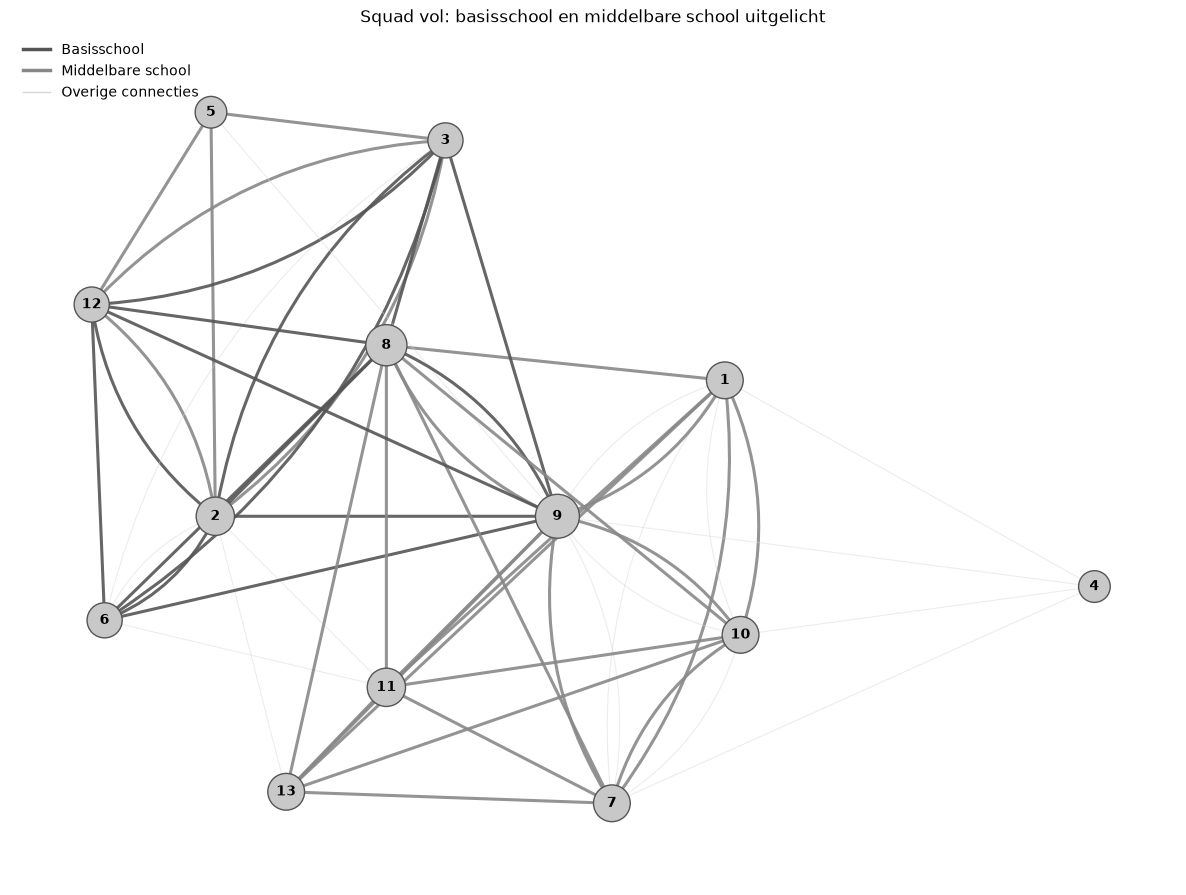

,nummer,auteur
0,1,Ijsie
1,2,Joel
2,3,Kevin
3,4,Marijn
4,5,Nick
5,6,Paul
6,7,Rheno
7,8,Rik
8,9,Rüberhaupt
9,10,Schwéhn


In [514]:
school_fig, school_ax = plt.subplots(figsize=(12, 9))
author_numbers = {
    author: str(index)
    for index, author in enumerate(sorted(plot_connections, key=str.casefold), start=1)
}
school_colors = {
    'basisschool': '#555555',
    'middelbare_school': '#888888',
}
for author_a, author_b, attributes in plot_connections.edges(data=True):
    relations = sorted(attributes['relations'])
    radii = [0.0] if len(relations) == 1 else np.linspace(-0.2, 0.2, len(relations))
    for relation, radius in zip(relations, radii, strict=True):
        highlighted = relation in school_colors
        school_ax.add_patch(FancyArrowPatch(
            central_positions[author_a], central_positions[author_b],
            arrowstyle='-', connectionstyle=f'arc3,rad={radius}',
            color=school_colors.get(relation, '#d6d6d6'),
            linewidth=2.2 if highlighted else 0.8,
            alpha=0.9 if highlighted else 0.45,
            shrinkA=9, shrinkB=9,
        ))
nx.draw_networkx_nodes(
    plot_connections, central_positions, ax=school_ax,
    node_size=[280 + 60 * author_degrees[author] for author in plot_connections],
    node_color='#c8c8c8', edgecolors='#555555', linewidths=1.0,
)
nx.draw_networkx_labels(
    plot_connections, central_positions, labels=author_numbers,
    ax=school_ax, font_size=10, font_weight='bold',
)
school_legend = [
    Line2D([0], [0], color=color, linewidth=2.5,
           label=relation.replace('_', ' ').capitalize())
    for relation, color in school_colors.items()
]
school_legend.append(Line2D([0], [0], color='#d6d6d6', linewidth=1.0,
                             label='Overige connecties'))
school_ax.legend(handles=school_legend, loc='upper left', frameon=False)
school_ax.set_title('Squad vol: basisschool en middelbare school uitgelicht')
x_positions = [position[0] for position in central_positions.values()]
y_positions = [position[1] for position in central_positions.values()]
school_ax.set_xlim(min(x_positions) - 0.15, max(x_positions) + 0.15)
school_ax.set_ylim(min(y_positions) - 0.15, max(y_positions) + 0.15)
school_ax.set_aspect('equal')
school_ax.set_axis_off()
school_fig.tight_layout()
display(school_fig)
plt.close(school_fig)
author_number_table = pd.DataFrame(
    [{'nummer': number, 'auteur': author} for author, number in author_numbers.items()]
).sort_values('nummer', key=lambda values: values.astype(int)).reset_index(drop=True)
display(author_number_table)

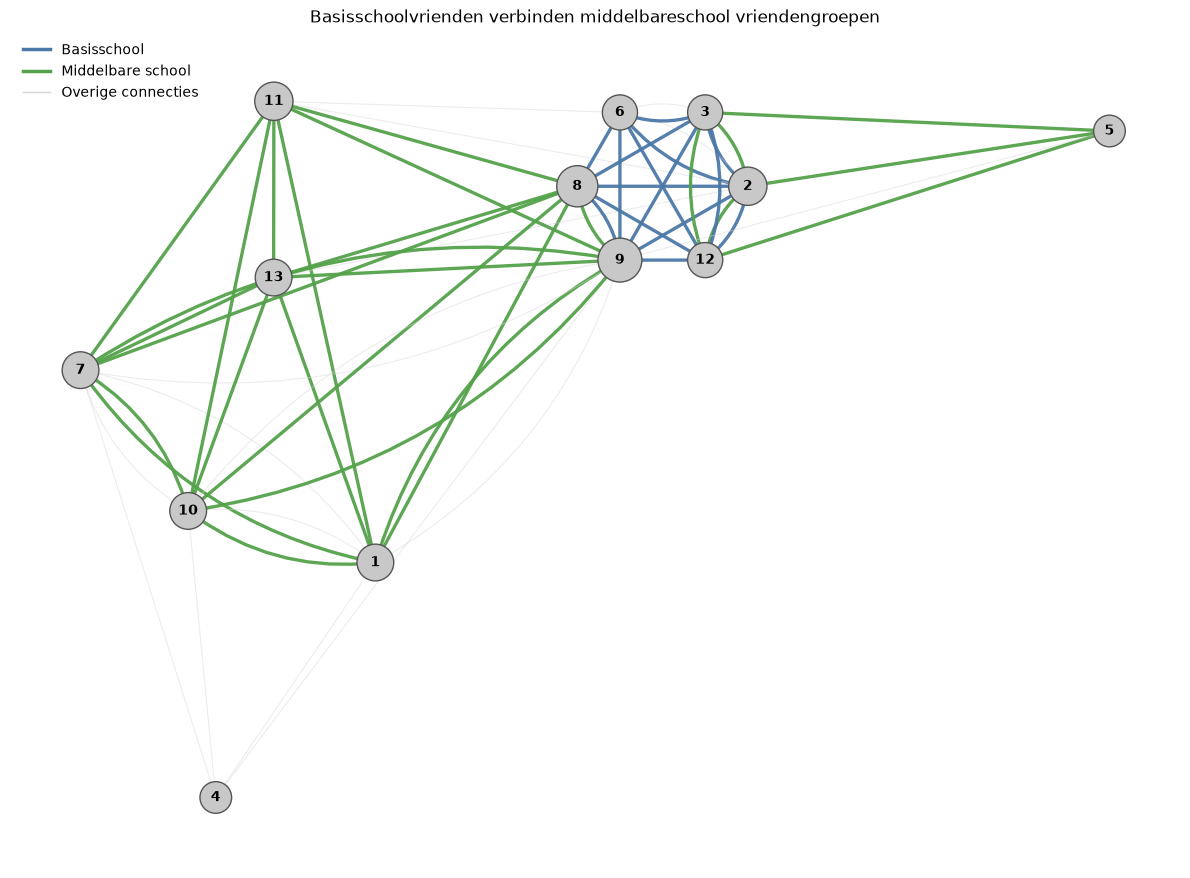

,nummer,auteur
0,1,Ijsie
1,2,Joel
2,3,Kevin
3,4,Marijn
4,5,Nick
5,6,Paul
6,7,Rheno
7,8,Rik
8,9,Rüberhaupt
9,10,Schwéhn


In [515]:
primary_school_group = connection_groups['basisschool'][0]
primary_positions = nx.circular_layout(plot_connections, scale=1.15)
for index, author in enumerate(primary_school_group):
    angle = 2 * np.pi * index / len(primary_school_group)
    primary_positions[author] = np.array([0.48 * np.cos(angle), 0.48 * np.sin(angle)])
for author_a, author_b in plot_connections.edges():
    plot_connections[author_a][author_b]['primary_layout_weight'] = (
        5.0 if 'basisschool' in plot_connections[author_a][author_b]['relations'] else 0.15
    )
primary_positions = nx.spring_layout(
    plot_connections, pos=primary_positions, fixed=primary_school_group, seed=46,
    k=1.0, iterations=300, weight='primary_layout_weight',
)
primary_extent = max(np.abs(position).max() for position in primary_positions.values())
primary_positions = {
    author: position * (1.3 / primary_extent)
    for author, position in primary_positions.items()
}
primary_author_numbers = {
    author: author_numbers[author] for author in plot_connections
}
primary_school_fig, primary_school_ax = plt.subplots(figsize=(12, 9))
school_colors = {'basisschool': '#4c78a8', 'middelbare_school': '#54a24b'}
for author_a, author_b, attributes in plot_connections.edges(data=True):
    relations = sorted(attributes['relations'])
    radii = [0.0] if len(relations) == 1 else np.linspace(-0.2, 0.2, len(relations))
    for relation, radius in zip(relations, radii, strict=True):
        highlighted = relation in school_colors
        primary_school_ax.add_patch(FancyArrowPatch(
            primary_positions[author_a], primary_positions[author_b],
            arrowstyle='-', connectionstyle=f'arc3,rad={radius}',
            color=school_colors.get(relation, '#d6d6d6'),
            linewidth=2.4 if highlighted else 0.8,
            alpha=0.95 if highlighted else 0.45,
            shrinkA=9, shrinkB=9,
        ))
nx.draw_networkx_nodes(
    plot_connections, primary_positions, ax=primary_school_ax,
    node_size=[280 + 60 * author_degrees[author] for author in plot_connections],
    node_color='#c8c8c8', edgecolors='#555555', linewidths=1.0,
)
nx.draw_networkx_labels(
    plot_connections, primary_positions, labels=primary_author_numbers,
    ax=primary_school_ax, font_size=10, font_weight='bold',
)
primary_legend = [
    Line2D([0], [0], color=color, linewidth=2.5,
           label=relation.replace('_', ' ').capitalize())
    for relation, color in school_colors.items()
]
primary_legend.append(Line2D([0], [0], color='#d6d6d6', linewidth=1.0,
                              label='Overige connecties'))
primary_school_ax.legend(handles=primary_legend, loc='upper left', frameon=False)
primary_school_ax.set_title('Basisschoolvrienden verbinden middelbareschool vriendengroepen')
x_positions = [position[0] for position in primary_positions.values()]
y_positions = [position[1] for position in primary_positions.values()]
primary_school_ax.set_xlim(min(x_positions) - 0.15, max(x_positions) + 0.15)
primary_school_ax.set_ylim(min(y_positions) - 0.15, max(y_positions) + 0.15)
primary_school_ax.set_aspect('equal')
primary_school_ax.set_axis_off()
primary_school_fig.tight_layout()
display(primary_school_fig)
plt.close(primary_school_fig)
display(author_number_table)

## Onderbouwing van de basisschoolconnecties

**Onderzoeksvraag:** hebben basisschoolconnecties ertoe geleid dat twee vriendengroepen één groep werden?

**Bron en publiek:** de connecties zijn gebaseerd op herinneringen van iemand die erbij was; de analyse is bedoeld voor een verslag.

**Wat de huidige plot kan laten zien:** welke auteurs volgens die herinnering bij dezelfde basisschoolgroep hoorden en hoe die opgegeven relaties samenhangen met de andere bekende connecties. De plot alleen toont geen volgorde in de tijd en kan daarom nog niet onderbouwen dat de basisschoolconnecties de samenvoeging hebben veroorzaakt.

**Voorlopige bewijsroute:** verduidelijk wat de twee vriendengroepen waren en wanneer ze één groep werden; leg vast waarop de herinnerde schoolrelaties en de groepsgeschiedenis berusten; vergelijk vervolgens de relaties vóór en na die periode. Beschrijf de huidige netwerkfiguur als een retrospectief, ongericht overzicht en vermeld onzekerheden of ontbrekende auteurs.

**Nog te bespreken:** wat één observatie is, hoe de twee vriendengroepen en het moment van samenvoeging worden vastgelegd, welke aanvullende herinneringen of bronnen beschikbaar zijn, en welke alternatieve verklaringen meespelen.

### Stage 2 — data en ontbrekende informatie

- **Observatie-eenheid:** een opgegeven connectie tussen twee auteurs.
- **Tijd:** de connecties vonden plaats vóór het begin van de chat; er is geen tijdlijn van het ontstaan of samengaan van de vriendengroepen.
- **Herkomst:** herinneringen van iemand die erbij was; er zijn nog geen aanvullende bronnen genoemd.
- **Gevolg voor de claim:** de huidige netwerkplot kan de herinnerde relaties tonen, maar zonder volgorde in de tijd kan zij niet vaststellen dat basisschoolconnecties de samenvoeging hebben veroorzaakt. Voor die causale stap is informatie nodig over groepslidmaatschap/contact vóór en na de verandering, of de claim moet als herinnerde interpretatie worden gepresenteerd.


### Stage 3 — welk patroon telt

Er is geen reden om alle aantallen of verdelingen te beschrijven. De gerichte verwachting is dat de twee middelbareschoolgroepen vooral via auteurs uit de basisschoolgroep met elkaar verbonden zijn. Een relevante controle is daarom de overlap/route tussen die groepen, naast eventuele directe verbindingen; dit is een relationeel patroon, geen bewijs van een historische oorzaak.


### Stage 4 — weergave

De gekozen weergaven zijn een netwerkplot en een membership-matrix (auteurs × schoolgroepen). De centrale vergelijking is of gedeelde basisschoollidmaatschappen de twee middelbareschoolgroepen met elkaar verbinden. De matrix moet groepslidmaatschap tonen; de netwerkplot toont de relatiestructuur. Beide tonen op zichzelf geen tijdsvolgorde of causaliteit.


### Stage 5 — visuele toets

De verwachte eerste indruk is: twee grote groepen, verbonden door auteurs met basisschoolconnecties. De claim krijgt tegenspraak als blijkt dat de middelbareschoolgroepen ook via een andere route verbonden zijn. De figuur en matrix moeten daarom expliciet laten zien welke auteurs in meerdere groepen voorkomen en welke schoolrelaties de route vormen.


### Stage 6 — verificatie en conclusie

Er zijn momenteel geen aanvullende bronnen of getuigen en geen tijdlijn; de connecties en interpretatie berusten op de herinnering van iemand die erbij was. De gebruiker kent geen andere verbindende factor, maar die is niet onafhankelijk uitgesloten. De huidige grafiek kan dus de herinnerde structuur illustreren, niet aantonen dat basisschoolconnecties de vriendengroepen hebben samengebracht.

**Verantwoorde formulering voor het verslag:** “Volgens mijn herinnering vormden de gedeelde basisschoolconnecties een belangrijke schakel tussen de twee vriendengroepen. De netwerkplot laat zien hoe de door mij opgegeven relaties de auteurs met elkaar verbinden. Omdat de relaties retrospectief zijn opgegeven en een tijdlijn ontbreekt, kan deze plot de historische volgorde of causaliteit niet zelfstandig vaststellen.”

**Sterkere onderbouwing als die later beschikbaar komt:** leg per auteur vast bij welke vriendengroep die hoorde vóór en na het samengaan, voeg waar mogelijk jaartallen/periodes toe, en toets de herinnering bij andere betrokkenen of met daterend materiaal. Toon daarnaast een membership-matrix (auteurs × schoolgroepen) naast de netwerkplot; rapporteer expliciet gedeelde auteurs en paden tussen de twee middelbareschoolgroepen. Noteer onzekerheid per opgegeven relatie.


## Sessies en interacties binnen Squad vol

Deze analyse gebruikt de Squad vol-chat. Een chatbrede sessie loopt door zolang er maximaal 60 minuten tussen opeenvolgende berichten zitten; een groter tijdsgat start een nieuwe sessie. Een interactie telt wanneer twee opeenvolgende berichten binnen dezelfde sessie van verschillende auteurs zijn. De ongerichte edge tussen die auteurs wordt één keer per overgang geteld; meerdere overgangen maken de verbinding dikker. Dit is een reproduceerbare proxy voor interactie, niet noodzakelijk bewijs dat een bericht expliciet aan de vorige auteur gericht was.

In [516]:
squad_vol_session_messages = (
    squad_vol_messages.dropna(subset=["timestamp", "author"])
    .sort_values("timestamp", kind="stable")
    .reset_index(drop=True)
    .copy()
)
message_gaps = squad_vol_session_messages["timestamp"].diff()
new_session = message_gaps.isna() | (message_gaps > pd.Timedelta(minutes=60))
squad_vol_session_messages["session_id"] = new_session.cumsum() - 1

squad_vol_session_messages["previous_author"] = (
    squad_vol_session_messages.groupby("session_id")["author"].shift()
)
author_changes = squad_vol_session_messages.loc[
    squad_vol_session_messages["previous_author"].notna()
    & squad_vol_session_messages["author"].ne(
        squad_vol_session_messages["previous_author"]
    ),
    ["previous_author", "author"],
].copy()
author_changes["authors"] = [
    tuple(sorted((previous, current), key=str.casefold))
    for previous, current in zip(
        author_changes["previous_author"], author_changes["author"], strict=True
    )
]
session_interactions = (
    author_changes.groupby("authors")
    .size()
    .rename("interactions")
    .reset_index()
)

session_interaction_graph = nx.Graph()
session_interaction_graph.add_nodes_from(
    squad_vol_session_messages["author"].unique()
)
for row in session_interactions.itertuples(index=False):
    author_a, author_b = row.authors
    session_interaction_graph.add_edge(
        author_a,
        author_b,
        weight=int(row.interactions),
        interactions=int(row.interactions),
    )

print(
    f"{squad_vol_session_messages.session_id.nunique():,} chatbrede sessies "
    f"(maximaal 60 minuten tussen opeenvolgende berichten); "
    f"{len(author_changes):,} overgangen tussen auteurs; "
    f"{session_interaction_graph.number_of_nodes()} auteurs en "
    f"{session_interaction_graph.number_of_edges()} verbindingen."
)
display(
    session_interactions.sort_values("interactions", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

6,754 chatbrede sessies (maximaal 60 minuten tussen opeenvolgende berichten); 38,074 overgangen tussen auteurs; 13 auteurs en 78 verbindingen.


,authors,interactions
0,"(Ijsie, Vincent Kruithof)",2284
1,"(Ijsie, Kevin)",2204
2,"(Ijsie, Schwéhn)",1903
3,"(Kevin, Vincent Kruithof)",1475
4,"(Kevin, Schwéhn)",1270
5,"(Ijsie, Paul)",1270
6,"(Schwéhn, Vincent Kruithof)",1171
7,"(Ijsie, Nick)",1170
8,"(Ijsie, Thijsje)",1158
9,"(Paul, Schwéhn)",1036


### Netwerk van opgegeven connecties

Deze grafiek gebruikt de opgegeven relaties uit cel 25. De gewenste afstand is 1 cm voor basisschool en korfbal, 2 cm voor middelbare school en 4 cm voor werk. Als een auteurs-paar meerdere relatietypen heeft, geldt de kortste afstand gedeeld door het aantal typen. De Kamada-Kawai-layout benadert deze afstanden ook via kortste routes; daardoor kunnen niet alle onderlinge afstanden in deze complexe graaf exact overeenkomen. Rüberhaupt staat centraal.

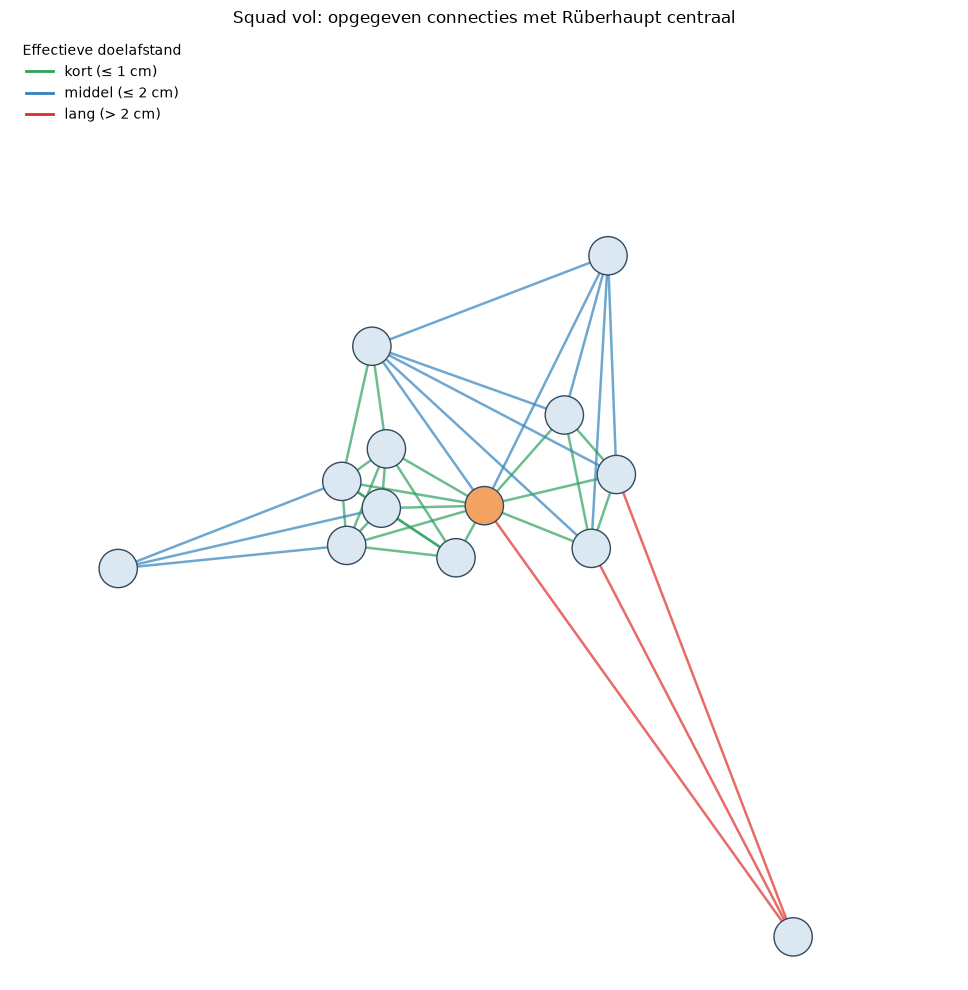

In [517]:
from matplotlib.lines import Line2D
relation_distances_cm = {
    "basisschool": 1,
    "middelbare_school": 2,
    "korfbal": 1,
    "werk": 4,
}
for author_a, author_b, attributes in combined_connections.edges(data=True):
    relations = attributes["relations"]
    shortest_relation_distance = min(
        relation_distances_cm[relation] for relation in relations
    )
    attributes["distance_cm"] = shortest_relation_distance / len(relations)

plot_connections = combined_connections.copy()
hidden_work_connections = {
    frozenset(("Nick", "Rüberhaupt")),
    frozenset(("Vincent Kruithof", "Joel")),
    frozenset(("Marijn", "Ijsie")),
}
hidden_school_connections = {
    frozenset(("Rik", "Thijsje")),
    frozenset(("Rik", "Vincent Kruithof")),
    frozenset(("Rik", "Ijsie")),
    frozenset(("Rik", "Schwéhn")),
    frozenset(("Rik", "Rheno")),
}
for author_a, author_b, attributes in list(plot_connections.edges(data=True)):
    if (
        frozenset((author_a, author_b)) in hidden_work_connections
        and attributes["relations"] == {"werk"}
    ):
        plot_connections.remove_edge(author_a, author_b)
    elif (
        frozenset((author_a, author_b)) in hidden_school_connections
        and attributes["relations"] == {"middelbare_school"}
    ):
        plot_connections.remove_edge(author_a, author_b)

connection_path_distances = dict(
    nx.floyd_warshall(plot_connections, weight="distance_cm")
)
connection_positions = nx.kamada_kawai_layout(
    plot_connections,
    dist=connection_path_distances,
    weight="distance_cm",
)
central_author = "Rüberhaupt"
central_position = connection_positions[central_author].copy()
connection_positions = {
    author: position - central_position
    for author, position in connection_positions.items()
}

distance_colors = {"kort": "#2ca25f", "middel": "#3182bd", "lang": "#de2d26"}
distance_labels = {"kort": "kort (≤ 1 cm)", "middel": "middel (≤ 2 cm)", "lang": "lang (> 2 cm)"}
connection_fig, connection_ax = plt.subplots(figsize=(13, 10))
for author_a, author_b, attributes in plot_connections.edges(data=True):
    distance = attributes["distance_cm"]
    distance_group = "kort" if distance <= 1 else "middel" if distance <= 2 else "lang"
    nx.draw_networkx_edges(
        plot_connections,
        connection_positions,
        edgelist=[(author_a, author_b)],
        ax=connection_ax,
        edge_color=distance_colors[distance_group],
        width=1.8,
        alpha=0.7,
    )

nx.draw_networkx_nodes(
    plot_connections,
    connection_positions,
    ax=connection_ax,
    node_size=760,
    node_color=[
        "#f4a261" if author == central_author else "#dbe8f2"
        for author in plot_connections
    ],
    edgecolors="#34495e",
    linewidths=1.0,
)
connection_ax.legend(
    handles=[
        Line2D([0], [0], color=color, linewidth=2, label=distance_labels[label])
        for label, color in distance_colors.items()
    ],
    title="Effectieve doelafstand",
    loc="upper left",
    frameon=False,
)
connection_ax.set_title("Squad vol: opgegeven connecties met Rüberhaupt centraal")
connection_ax.set_aspect("equal")
layout_extent = max(
    np.max(np.abs(np.concatenate(list(connection_positions.values())))) * 1.1,
    1.0,
)
connection_ax.set_xlim(-layout_extent, layout_extent)
connection_ax.set_ylim(-layout_extent, layout_extent)
connection_ax.set_axis_off()
connection_fig.tight_layout()
display(connection_fig)
plt.close(connection_fig)

In [518]:
mean_connection_distance = {
    author: np.mean([
        attributes["distance_cm"]
        for _, _, attributes in combined_connections.edges(author, data=True)
    ])
    for author in combined_connections
}
interaction_counts = {
    tuple(sorted(authors, key=str.casefold)): int(interactions)
    for authors, interactions in session_interactions[
        ["authors", "interactions"]
    ].itertuples(index=False, name=None)
}
mean_interactions_by_author = {
    author: np.mean([
        interactions
        for authors, interactions in interaction_counts.items()
        if author in authors
    ])
    for author in combined_connections
}

connection_author_metrics = pd.DataFrame({
    "degree": dict(combined_connections.degree()),
    "betweenness": nx.betweenness_centrality(combined_connections),
    "clustering_coefficient": nx.clustering(combined_connections),
    "gemiddelde_afstand_cm": mean_connection_distance,
    "gemiddelde_interacties_per_interactiepartner": mean_interactions_by_author,
}).rename_axis("author").sort_values(
    "betweenness", ascending=False
).reset_index()

display(
    connection_author_metrics.style.format({
        "betweenness": "{:.4f}",
        "clustering_coefficient": "{:.4f}",
        "gemiddelde_afstand_cm": "{:.2f}",
        "gemiddelde_interacties_per_interactiepartner": "{:,.2f}",
    })
)

,author,degree,betweenness,clustering_coefficient,gemiddelde_afstand_cm,gemiddelde_interacties_per_interactiepartner
0,Rüberhaupt,12,0.2487,0.5152,1.62,219.33
1,Rik,10,0.0934,0.6222,1.45,108.92
2,Joel,8,0.0442,0.6786,1.31,447.75
3,Thijsje,8,0.0303,0.7500,1.75,449.67
4,Ijsie,7,0.0114,0.8571,1.86,"1,120.75"
5,Vincent Kruithof,7,0.0114,0.8571,2.29,788.08
6,Schwéhn,7,0.0114,0.8571,1.86,748.08
7,Rheno,7,0.0114,0.8571,1.86,304.67
8,Kevin,6,0.0076,0.8667,0.92,848.08
9,Paul,6,0.0076,0.8667,0.83,526.17


In [ ]:
from matplotlib.lines import Line2D
relation_distances_cm = {
    "basisschool": 1,
    "middelbare_school": 2,
    "korfbal": 1,
    "werk": 4,
}
for author_a, author_b, attributes in combined_connections.edges(data=True):
    relations = attributes["relations"]
    shortest_relation_distance = min(
        relation_distances_cm[relation] for relation in relations
    )
    attributes["distance_cm"] = shortest_relation_distance / len(relations)

plot_connections = combined_connections.copy()
hidden_work_connections = {
    frozenset(("Nick", "Rüberhaupt")),
    frozenset(("Vincent Kruithof", "Joel")),
    frozenset(("Marijn", "Ijsie")),
}
hidden_school_connections = {
    frozenset(("Rik", "Thijsje")),
    frozenset(("Rik", "Vincent Kruithof")),
    frozenset(("Rik", "Ijsie")),
    frozenset(("Rik", "Schwéhn")),
    frozenset(("Rik", "Rheno")),
}
for author_a, author_b, attributes in list(plot_connections.edges(data=True)):
    if (
        frozenset((author_a, author_b)) in hidden_work_connections
        and attributes["relations"] == {"werk"}
    ):
        plot_connections.remove_edge(author_a, author_b)
    elif (
        frozenset((author_a, author_b)) in hidden_school_connections
        and attributes["relations"] == {"middelbare_school"}
    ):
        plot_connections.remove_edge(author_a, author_b)

connection_path_distances = dict(
    nx.floyd_warshall(plot_connections, weight="distance_cm")
)
connection_positions = nx.kamada_kawai_layout(
    plot_connections,
    dist=connection_path_distances,
    weight="distance_cm",
)
central_author = "Rüberhaupt"
central_position = connection_positions[central_author].copy()
connection_positions = {
    author: position - central_position
    for author, position in connection_positions.items()
}

distance_colors = {"kort": "#2ca25f", "middel": "#3182bd", "lang": "#de2d26"}
distance_labels = {"kort": "kort (≤ 1 cm)", "middel": "middel (≤ 2 cm)", "lang": "lang (> 2 cm)"}
connection_fig, connection_ax = plt.subplots(figsize=(13, 10))
for author_a, author_b, attributes in plot_connections.edges(data=True):
    distance = attributes["distance_cm"]
    distance_group = "kort" if distance <= 1 else "middel" if distance <= 2 else "lang"
    nx.draw_networkx_edges(
        plot_connections,
        connection_positions,
        edgelist=[(author_a, author_b)],
        ax=connection_ax,
        edge_color=distance_colors[distance_group],
        width=1.8,
        alpha=0.7,
    )

nx.draw_networkx_nodes(
    plot_connections,
    connection_positions,
    ax=connection_ax,
    node_size=760,
    node_color=[
        "#f4a261" if author == central_author else "#dbe8f2"
        for author in plot_connections
    ],
    edgecolors="#34495e",
    linewidths=1.0,
)
nx.draw_networkx_labels(
    plot_connections,
    connection_positions,
    ax=connection_ax,
    font_size=9,
)
connection_ax.legend(
    handles=[
        Line2D([0], [0], color=color, linewidth=2, label=distance_labels[label])
        for label, color in distance_colors.items()
    ],
    title="Effectieve doelafstand",
    loc="upper left",
    frameon=False,
)
connection_ax.set_title("Van oprichter naar stille vennoot.", fontsize=16, pad=24)
connection_ax.text(
    0.5,
    1.02,
    "Auteur 9 bracht de groep bij elkaar, maar is niet de actiefste vriend",
    transform=connection_ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=11,
)
connection_ax.set_aspect("equal")
layout_extent = max(
    np.max(np.abs(np.concatenate(list(connection_positions.values())))) * 1.1,
    1.0,
)
connection_ax.set_xlim(-layout_extent, layout_extent)
connection_ax.set_ylim(-layout_extent, layout_extent)
connection_ax.set_axis_off()
connection_fig.tight_layout(rect=(0, 0, 1, 0.94))
interaction_counts = {
    tuple(sorted(authors, key=str.casefold)): int(interactions)
    for authors, interactions in session_interactions[["authors", "interactions"]]
    .itertuples(index=False, name=None)
}
maximum_edge_interactions = max(
    (interaction_counts.get(tuple(sorted(edge, key=str.casefold)), 0)
     for edge in plot_connections.edges()),
    default=1,
)
connection_ax.get_legend().remove()
edge_collections = connection_ax.collections[:plot_connections.number_of_edges()]
for (author_a, author_b), edge_artist in zip(
    plot_connections.edges(), edge_collections, strict=True
):
    pair = tuple(sorted((author_a, author_b), key=str.casefold))
    interactions = interaction_counts.get(pair, 0)
    edge_color = (
        "#2ca25f" if interactions >= 500
        
        else "#777777"
    )
    edge_artist.set_color(edge_color)
    edge_artist.set_linewidth(
        0.6 + 4.4 * np.sqrt(interactions / maximum_edge_interactions)
    )
node_collection = connection_ax.collections[plot_connections.number_of_edges()]
node_collection.set_facecolor("#dbe8f2")
for label in connection_ax.texts:
    label.remove()
author_numbers = {
    author: str(number)
    for number, author in enumerate(
        sorted(plot_connections.nodes(), key=str.casefold),
        start=1,
    )
}
nx.draw_networkx_labels(
    plot_connections,
    connection_positions,
    labels=author_numbers,
    ax=connection_ax,
    font_size=10,
    font_weight="bold",
)
connection_ax.text(
    0.5,
    1.02,
    "Auteur 9 bracht de groep bij elkaar, maar is niet de actiefste vriend",
    transform=connection_ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=11,
)

interaction_weight_legend = connection_ax.legend(
    handles=[
        Line2D(
            [0], [0], color="#777777",
            linewidth=0.6 + 4.4 * np.sqrt(value / maximum_edge_interactions),
            label=f"{value:,} interacties",
        )
        for value in sorted({int(round(maximum_edge_interactions / 2)), maximum_edge_interactions})
    ] + [
        Line2D([0], [0], color="#2ca25f", linewidth=2, label="≥500 interacties (groen)"),
        
    ],
    title="Lijndikte: interacties per auteurs-paar",
    loc="upper right",
    frameon=False,
)
connection_ax.add_artist(interaction_weight_legend)
display(connection_fig)
plt.close(connection_fig)
from IPython.display import Markdown
display(Markdown(
    "**Afstand tussen punten:** de layout benadert de opgegeven relatie-afstanden: "
    "basisschool en korfbal 1 cm, middelbare school 2 cm en werk 4 cm. "
    "Bij meerdere relatietypen tussen een paar geldt de kortste afstand gedeeld door "
    "het aantal typen. De posities zijn een visuele layout op basis van kortste routes; "
    "de afstanden op het scherm zijn dus geen exacte centimeters.\n\n"
    "**Interactie:** een interactie telt wanneer twee opeenvolgende berichten binnen "
    "dezelfde sessie (maximaal 60 minuten ertussen) van verschillende auteurs zijn. "
    "Herhaalde overgangen tussen hetzelfde paar verhogen de telling en maken de lijn dikker. "
    "Dit is geen bewijs dat een bericht rechtstreeks aan de andere auteur gericht was."
))
author_number_table = pd.DataFrame(
    [{"nummer": number, "auteur": author} for author, number in author_numbers.items()]
).sort_values("nummer", key=lambda values: values.astype(int)).reset_index(drop=True)
display(author_number_table)